# Supplier Segmentation & Churn — which milk suppliers matter most, and which are about to side-sell?

**Author:** Fordrane Albert Okumu · **Tools:** Python (pandas, scikit-learn, statsmodels, matplotlib)
**Companion:** the same features, segmentation and churn model rebuilt in base R live in [`R/supplier_segmentation_churn.R`](../R/supplier_segmentation_churn.R).

---

## 0. Why a dairy processor needs supplier analytics

A dairy processor can only sell what its farmers deliver. Raw milk arrives every morning at **collection centres**, where it is tested (fat, solids-not-fat, acidity, antibiotics, added water), cooled and trucked to the factory. Three things make the supplier base a strategic asset rather than a purchasing detail:

1. **Supply security.** Plants are built for a certain intake. When intake falls, fixed costs are spread over fewer litres and customer orders for fresh milk, yoghurt and cheese go short.
2. **Competition at the farm gate.** Competing processors and informal brokers buy milk for cash, often at the farm gate. A farmer who is unhappy with price, payment speed or service doesn't need to "cancel" anything. They just start selling some, then all, of their milk elsewhere (**side-selling**).
3. **Seasonality.** Kenya has two rainy seasons. Milk is abundant in the **flush** (roughly April–June and November–December) and scarce in the **dry** months (January–March and July–September). In the dry season competitors bid prices up exactly when every litre is hardest to replace. **A litre lost in August costs far more than a litre lost in May.**

This notebook answers two questions:

* **Segmentation:** *who are our suppliers?* Which ones carry our volume, which are reliable, which bring quality problems, and which are small but worth developing?
* **Churn:** *which suppliers are about to stop delivering, why, and how many litres would we lose?* Then: *what is it worth spending to keep them?*

### The data

The data is **synthetic**. It was generated by [`data/generate_data.py`](../data/generate_data.py) to resemble the milk-collection records of a mid-sized Kenyan processor: about 6,000 registered suppliers (smallholder farmers, farmer groups / cooperatives and commercial farms) delivering to **10 collection centres in 8 counties** from January 2025 to September 2026. Hidden drivers (price competition, payment delays, rejections, distance, extension coverage, input credit, group membership and an unobserved loyalty trait) shape behaviour, but, as in a real ERP, **only observable records are exported**. No real company, farmer or price data is used.

| File | One row per | Key columns |
|---|---|---|
| `suppliers.csv` | supplier | type, centre, county, registration date, herd size, distance to centre, payment method (M-Pesa / bank), farmer-group member |
| `deliveries_weekly.csv.gz` | supplier × collection week | days delivered, litres delivered, litres rejected and reason, fat %, SNF % |
| `payments_monthly.csv` | supplier × month | base price, quality & volume bonus, price per litre, credit deduction, due date, paid date, **payment delay** |
| `market_prices.csv` | county × month | our base price and the **competitor farm-gate price** (field-officer survey) |
| `extension_visits.csv` | visit | extension officer, vet / AI service, quality training |
| `input_credit.csv` | advance | dairy meal, mineral lick, AI service, fodder seed (recovered from milk payments) |

Deliveries are stored **weekly** (one row per supplier-week) rather than daily, which keeps the file small while preserving everything the analysis needs: volume, delivery days, quality and rejections.

## 1. Setup

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, roc_auc_score, roc_curve, average_precision_score,
                             brier_score_loss, confusion_matrix, precision_score, recall_score)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.inspection import permutation_importance

ROOT = Path.cwd().parent if Path.cwd().name == "python" else Path.cwd()
sys.path.insert(0, str(ROOT / "python"))
from features import (load, build_features, churn_label, is_test, CUTOFF, ACTIVE_DAYS, GRACE_DAYS, SILENT_DAYS)

OUT = ROOT / "outputs" / "python"; OUT.mkdir(parents=True, exist_ok=True)
TEAL, AMBER, GREY, RED = "#0f766e", "#b45309", "#94a3b8", "#b91c1c"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})
pd.set_option("display.width", 170, "display.max_columns", 30)
DRY_MONTHS = [1, 2, 3, 7, 8, 9]

## 2. Load the data and check its quality

Before any modelling, check that the records make sense. Each check below protects against a specific way that milk-collection data goes wrong in practice:

* **Duplicates** (the same supplier-week recorded twice) would double-count litres.
* **Rejected litres greater than delivered litres**, or **impossible fat / SNF readings**, point to data-entry or analyser errors.
* **Deliveries from unregistered suppliers** break traceability.
* **Reconciliation:** the litres paid for each month should equal the litres accepted at the centre (delivered minus rejected). This is the same check a dairy ERP runs before payroll for farmers is released.

In [2]:
sup, dl, pay, mkt, vis, cred = load()
print(f"{len(sup):,} registered suppliers | {len(dl):,} supplier-weeks | {dl.litres_delivered.sum()/1e6:,.1f}m litres | "
      f"{dl.week_ending.min():%d %b %Y} - {dl.week_ending.max():%d %b %Y}")
print(f"{len(pay):,} monthly payments | {len(vis):,} visits | {len(cred):,} input-credit advances | {len(mkt)} county-month prices")

acc = dl.assign(month=dl.week_ending.dt.to_period("M").astype(str),
                accepted=dl.litres_delivered - dl.litres_rejected).groupby(["supplier_id", "month"]).accepted.sum()
rec = pay.set_index(["supplier_id", "month"]).litres_accepted.to_frame().join(acc)
quality = pd.Series({
    "missing values (deliveries, excl. blank rejection reason)": int(dl.drop(columns="rejection_reason").isna().sum().sum()),
    "duplicate supplier-weeks": int(dl.duplicated(["supplier_id", "week_ending"]).sum()),
    "weeks with litres <= 0": int((dl.litres_delivered <= 0).sum()),
    "weeks with rejected > delivered": int((dl.litres_rejected > dl.litres_delivered + 1e-9).sum()),
    "fat % outside 2.5-6.0": int((~dl.fat_pct.between(2.5, 6.0)).sum()),
    "SNF % outside 7.5-9.5": int((~dl.snf_pct.between(7.5, 9.5)).sum()),
    "deliveries from unregistered suppliers": int((~dl.supplier_id.isin(sup.supplier_id)).sum()),
    "payments that don't reconcile with accepted litres (> 1 L)": int(((rec.litres_accepted - rec.accepted).abs() > 1).sum()),
}, name="count")
display(quality.to_frame())
display(sup.supplier_type.value_counts().rename("registered suppliers").to_frame()
        .assign(share=lambda d: (d["registered suppliers"] / d["registered suppliers"].sum()).round(3)))

6,000 registered suppliers | 218,733 supplier-weeks | 175.4m litres | 05 Jan 2025 - 27 Sep 2026
51,872 monthly payments | 10,934 visits | 3,936 input-credit advances | 168 county-month prices


,count
"missing values (deliveries, excl. blank rejection reason)",0
duplicate supplier-weeks,0
weeks with litres <= 0,0
weeks with rejected > delivered,0
fat % outside 2.5-6.0,0
SNF % outside 7.5-9.5,0
deliveries from unregistered suppliers,0
payments that don't reconcile with accepted litres (> 1 L),0


,registered suppliers,share
supplier_type,,
Smallholder,5071,0.845
Commercial farm,654,0.109
Farmer group/cooperative,275,0.046


**Interpretation:** every check passes. No duplicate weeks, no impossible quality readings, no deliveries from unknown suppliers, and every monthly payment reconciles to the litres accepted at the centre. Smallholder farmers are the large majority of registered suppliers. As the next sections show, they deliver a much smaller share of the milk.

### The business context in three charts

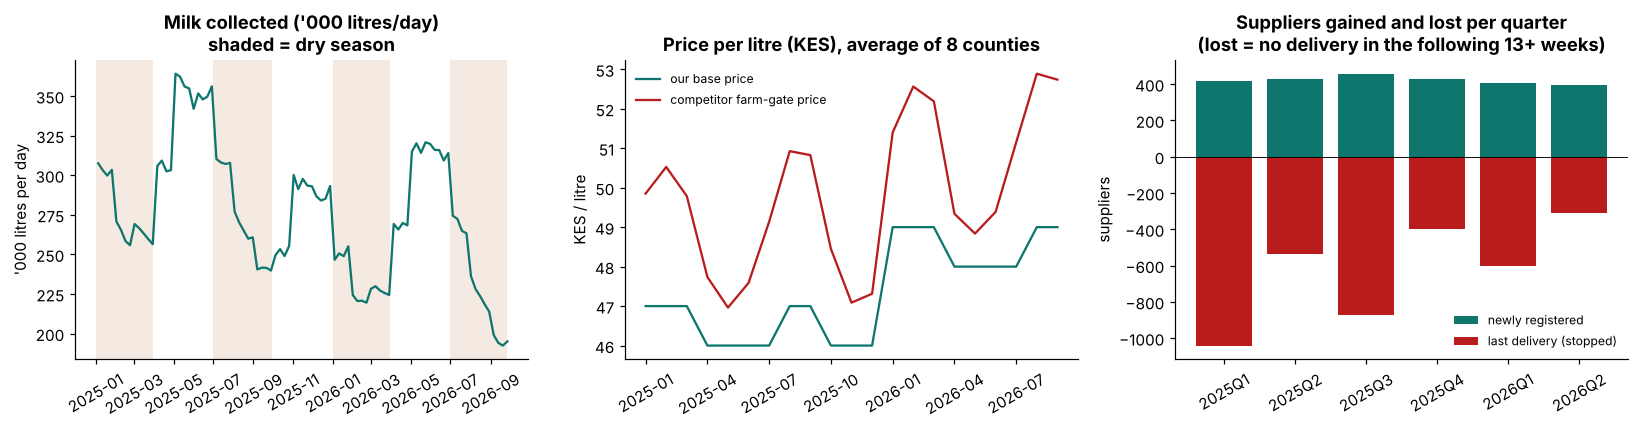

Active suppliers per week: 1,593 - 3,426 | competitor premium over our base price: flush months +1.4 KES, dry months +3.3 KES
Daily intake: 364,079 L/day at peak flush week vs 192,416 L/day at the lowest week


,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2
joined,419,426,457,430,407,396
stopped,1041,534,870,398,602,312


In [3]:
wk = dl.groupby("week_ending").agg(litres=("litres_delivered", "sum"), suppliers=("supplier_id", "nunique"))
m = mkt.assign(premium=mkt.competitor_price_kes - mkt.base_price_kes).groupby("month").agg(
    base=("base_price_kes", "mean"), competitor=("competitor_price_kes", "mean"), premium=("premium", "mean"))
last = dl.groupby("supplier_id").week_ending.max()
new = sup[sup.registered_date >= "2025-01-01"].registered_date       # suppliers registered before 2025 are not "gained"
flows = pd.DataFrame({"joined": new.dt.to_period("Q").value_counts(),
                      "stopped": last[last < dl.week_ending.max() - pd.Timedelta(days=91)].dt.to_period("Q").value_counts()}).fillna(0).sort_index()

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(wk.index, wk.litres / 7 / 1000, color=TEAL)
for y in (2025, 2026):
    for a, b in ((f"{y}-01-01", f"{y}-03-31"), (f"{y}-07-01", f"{y}-09-30")):
        ax[0].axvspan(pd.Timestamp(a), min(pd.Timestamp(b), wk.index.max()), color=AMBER, alpha=.12, lw=0)
ax[0].set(title="Milk collected ('000 litres/day)\nshaded = dry season", ylabel="'000 litres per day")
ax[0].tick_params(axis="x", rotation=30)
x = np.arange(len(m))
ax[1].plot(x, m.base, color=TEAL, label="our base price"); ax[1].plot(x, m.competitor, color=RED, label="competitor farm-gate price")
ax[1].set_xticks(x[::3], m.index[::3], rotation=30); ax[1].legend(frameon=False, fontsize=8)
ax[1].set(title="Price per litre (KES), average of 8 counties", ylabel="KES / litre")
flows = flows.loc[:"2026Q2"]                                           # Q3 2026 exits can't be confirmed yet
ax[2].bar(flows.index.astype(str), flows.joined, color=TEAL, label="newly registered")
ax[2].bar(flows.index.astype(str), -flows.stopped, color=RED, label="last delivery (stopped)")
ax[2].axhline(0, color="black", lw=.6); ax[2].tick_params(axis="x", rotation=30); ax[2].legend(frameon=False, fontsize=8)
ax[2].set(title="Suppliers gained and lost per quarter\n(lost = no delivery in the following 13+ weeks)", ylabel="suppliers")
fig.tight_layout(); fig.savefig(OUT / "01_supply_context.png", dpi=150); plt.show()
print(f"Active suppliers per week: {wk.suppliers.min():,} - {wk.suppliers.max():,} | "
      f"competitor premium over our base price: flush months {m.premium[[int(p[-2:]) not in DRY_MONTHS for p in m.index]].mean():+.1f} KES, "
      f"dry months {m.premium[[int(p[-2:]) in DRY_MONTHS for p in m.index]].mean():+.1f} KES")
print(f"Daily intake: {wk.litres.max()/7:,.0f} L/day at peak flush week vs {wk.litres.min()/7:,.0f} L/day at the lowest week")
flows.astype(int).T

**Interpretation:**

* **Seasonality is large.** Daily intake swings from about **364,000 litres/day** in the peak flush week (early May 2025) to about **192,000** in the lowest week (September 2026). Quarterly averages fall from about 339,000 L/day in Q2 2025 to about 271,000 in Q3 2025. The plant has to plan around a dry-season trough every year.
* **Competitors bid hardest when milk is scarce.** On average across counties and months, the surveyed competitor farm-gate price is **KES 1.4 above our base price in flush months and KES 3.3 above it in dry months**. Our base price follows only partly. That gap is the main side-selling pressure.
* **The supplier base is eroding.** Every quarter, roughly 400–460 new suppliers register, but in four of the six complete quarters more suppliers stopped delivering than joined. Exits peak in the dry quarters (Q1 and Q3 2025: 1,041 and 870). The number of suppliers delivering in a given week fell from 3,426 in the first week of 2025 to 2,147 in the snapshot week. (Part of the early fall is an artefact of how the synthetic history starts. See the limitations section.) Replacing lost suppliers costs recruitment effort, and new suppliers start small.

## 3. The single most important design decision: a leakage-safe snapshot

A churn model must predict the **future** using only what was known in the **past**. If information from after the prediction date leaks into the features, the model looks brilliant in testing and fails in production.

We take a **snapshot on Sunday 28 June 2026**, the end of the last full collection week of June, as the long-rains flush ends and the July–September dry season begins:

```
 Jan 2025 ────────── OBSERVATION (features) ────────── 28 Jun 2026 ── grace: 4 weeks ── SILENT WINDOW: 9 weeks (63 days) ── 27 Sep 2026
                                                          snapshot      (26 Jul 2026)        churn = zero deliveries here
```

* **Population:** suppliers who are **active** at the snapshot, i.e. delivered at least once in the 4 weeks up to 28 June.
* **Churn = 1** if the supplier makes **no delivery at all in the 63 days (9 weekly cycles) from 27 July to 27 September 2026**. In words: the supplier stops within about a month of the snapshot and then stays away for at least 60 days.
* **Why a 4-week grace period?** Leavers often *fade* first: they divert some days' milk to a broker, then all of it. A supplier who is already fading at the snapshot will still deliver a few litres in early July. Requiring zero deliveries from day 1 would label these suppliers "retained" even though they are clearly leaving. The grace period gives the model about a month of lead time to act on.
* **Why 63 days of silence?** Small herds sometimes stop for a few weeks when a cow dries off or falls sick, then come back. In this data those pauses last at most 7 weeks, so 9 silent weeks separates real churn from temporary pauses.
* **Features** use only records that existed on 28 June: deliveries up to that week, **payments that had actually been paid by then** (June's milk is paid on 10 July or later, so it is excluded), competitor prices for the same months, and visits and credit dated on or before the snapshot.

In production, the same code runs every month with a new snapshot date and scores every active supplier.

## 4. Feature engineering — turning collection records into supplier behaviour

Each feature captures one aspect of the supplier relationship:

| Feature | Definition | Why it matters |
|---|---|---|
| `litres_per_day_52w` | Litres in the last 52 weeks ÷ observable days | **Volume**: how much supply the supplier represents |
| `avg_daily_litres_13w` | Litres ÷ delivery days, last 13 weeks | Current size per delivery day |
| `delivery_day_share_13w` | Delivery days ÷ possible days, last 13 weeks | **Consistency**: does the milk come every day? |
| `litres_cv_26w` | Coefficient of variation (SD ÷ mean) of weekly litres, last 26 weeks | **Volatility**: steady or erratic supply |
| `litres_trend` | Avg weekly litres in the last 8 weeks ÷ the 18 weeks before, **divided by the same ratio for the supplier's centre** | **Fading**: < 1 means falling *faster than the season explains* |
| `fat_pct`, `snf_pct` | Litre-weighted fat and solids-not-fat %, last 26 weeks | Milk composition, which drives the quality bonus and product yield |
| `rejection_rate` | Rejected ÷ delivered litres, last 26 weeks (plus antibiotic / adulteration flags) | **Quality risk** and income lost by the farmer |
| `price_realised_kes` | Gross pay ÷ accepted litres, last 3 paid months | What we actually pay, including bonuses |
| `price_gap_kes` | Competitor farm-gate price in the supplier's county − `price_realised_kes` | **Side-selling pressure**: > 0 means competitors pay more |
| `payment_delay_days` | Average days paid after the due date, last 3 paid months | Cash-flow pain for the farmer |
| `distance_km` | Distance from farm to centre | Transport cost and effort per litre |
| `advisory_visits_180d` | Extension-officer and vet / AI visits, last 180 days | Service relationship |
| `quality_training_180d` | Quality-training visits (triggered after rejections), last 180 days | Corrective support |
| `has_credit`, `credit_balance_kes` | Outstanding input-credit (feeds) balance | **Lock-in**: the advance is recovered from milk payments |
| `tenure_months`, `group_member`, `pays_bank`, `supplier_type` | Attributes | Relationship history, cooperative ties, payment channel |

Two design details matter:

* **Seasonality-adjusted trend.** Every supplier's milk rises in the flush and falls in the dry season. Comparing a supplier's ratio with the ratio for *the whole centre* removes the shared seasonal swing, so `litres_trend` picks up only supplier-specific decline.
* **Observable weeks.** A supplier who joined 5 weeks ago has 5 observable weeks, not 13 or 26. Every rate is divided by the weeks the supplier could actually have delivered. Otherwise new suppliers would look erratic.

In [4]:
F = build_features(sup, dl, pay, mkt, vis, cred)
print(f"Feature table: {F.shape[0]:,} suppliers x {F.shape[1]} columns (suppliers with at least one delivery before the snapshot) | "
      f"{F.no_payment_yet.sum()} recent joiners not yet paid by the snapshot (price gap and delay set to their centre's median)")
F.describe().T[["mean", "50%", "min", "max"]].round(2)

Feature table: 5,930 suppliers x 36 columns (suppliers with at least one delivery before the snapshot) | 105 recent joiners not yet paid by the snapshot (price gap and delay set to their centre's median)


,mean,50%,min,max
recency_days,201.23,154.00,0.00,539.00
weeks_since_first_delivery,61.90,78.00,1.00,78.00
litres_365d,16644.31,1516.00,0.00,961144.80
litres_13w,4624.76,0.00,0.00,265689.60
days_delivered_13w,29.64,0.00,0.00,91.00
litres_per_day_52w,56.98,6.45,0.00,2640.51
delivery_day_share_13w,0.35,0.00,0.00,1.00
avg_daily_litres_13w,60.36,0.00,0.00,3100.20
litres_cv_26w,0.35,0.14,0.00,5.10
litres_trend,0.75,0.78,0.10,1.88


---
# PART A — SUPPLIER SEGMENTATION

We segment the **current supply base**: the suppliers active at the snapshot (at least one delivery in the 4 weeks to 28 June 2026). This is the same population the churn model scores in Part B, so every supplier ends up with both a **segment** and a **churn risk**.

In [5]:
S = F[F.recency_days < ACTIVE_DAYS].copy()
lapsed = F[(F.recency_days >= ACTIVE_DAYS) & (F.litres_365d > 0)]
print(f"Active suppliers at snapshot: {len(S):,} | delivering {S.litres_per_day_52w.sum():,.0f} litres/day on average over the last year")
print(f"Not active but delivered in the last 12 months (win-back pool, not segmented): {len(lapsed):,} suppliers, "
      f"whose last-12-month deliveries averaged {lapsed.litres_365d.sum()/364:,.0f} litres/day")
S.groupby("supplier_type").agg(suppliers=("supplier_id", "size"), litres_per_day=("litres_per_day_52w", "sum"),
                               median_litres_per_day=("litres_per_day_52w", "median")) \
 .assign(supplier_share=lambda d: d.suppliers / d.suppliers.sum(), litres_share=lambda d: d.litres_per_day / d.litres_per_day.sum()).round(3)

Active suppliers at snapshot: 2,229 | delivering 278,699 litres/day on average over the last year
Not active but delivered in the last 12 months (win-back pool, not segmented): 2,126 suppliers, whose last-12-month deliveries averaged 52,445 litres/day


,suppliers,litres_per_day,median_litres_per_day,supplier_share,litres_share
supplier_type,,,,,
Commercial farm,228,108941.171,377.192,0.102,0.391
Farmer group/cooperative,219,133352.859,519.787,0.098,0.478
Smallholder,1782,36405.089,17.066,0.799,0.131


**Interpretation:** this is the central fact of the supply base. **Smallholders are 80% of active suppliers but deliver only 13% of the milk.** About 220 farmer groups / cooperatives (48% of litres) and about 230 commercial farms (39%) deliver the rest. Supplier *count* and supply *volume* point to very different priorities, which is why we segment on volume, reliability and quality rather than on supplier type alone.

Another **2,126 suppliers** delivered at some point in the 12 months before the snapshot but not in the last 4 weeks. Over the last year they averaged about 52,000 litres/day between them. They form a *win-back pool*, outside the scope of this segmentation.

## 5. A supplier value framework: volume × reliability × quality

Customer segmentation often uses RFM. For **suppliers**, the questions are different: *how much milk do they bring (volume), can we count on it (reliability), is it good milk (quality), and is it slipping away (trend)?* We combine these into a transparent, rule-based framework.

**Step 1: ABC volume classes (Pareto).** Rank suppliers by litres per day and accumulate their share of total volume:

* **A** = the suppliers who together make up the first **80%** of litres
* **B** = the next **15%**
* **C** = the last **5%**

ABC classification is standard in procurement and inventory management. It sets the volume tiers by *contribution* instead of arbitrary litre cut-offs.

**Step 2: three behavioural flags.**

* **Reliable:** delivers on at least 85% of possible days in the last 13 weeks **and** weekly volume CV ≤ 0.30.
* **Quality risk:** rejection rate ≥ 3% of litres in the last 26 weeks. That is about twice the rejection rate of the whole collection.
* **Fading:** seasonality-adjusted trend < 0.75, or no delivery in the last 2 weeks before the snapshot.

**Step 3: segments, applied in order of urgency:**

| Order | Segment | Rule | Why it gets its own strategy |
|---|---|---|---|
| 1 | **At-risk** | Fading, and class A or B | Volume that is visibly leaving; act now |
| 2 | **Quality-risk** | Rejection rate ≥ 3% (any class) | Costs money in rejected milk and can contaminate a whole tanker |
| 3 | **Strategic** | Class A and reliable | The backbone of supply: protect it |
| 4 | **Core** | Class A not reliable, or class B | Meaningful volume: stabilise and grow |
| 5 | **Developing** | Class C and reliable | Small but dependable: grow through extension and inputs |
| 6 | **Low-value** | Class C and not reliable, or class C and fading | Small and erratic: serve at lowest cost |

In [6]:
S = S.sort_values("litres_per_day_52w", ascending=False)
cum_before = S.litres_per_day_52w.cumsum().shift(fill_value=0) / S.litres_per_day_52w.sum()
S["abc_class"] = np.select([cum_before < .80, cum_before < .95], ["A", "B"], "C")
S["reliable"] = (S.delivery_day_share_13w >= .85) & (S.litres_cv_26w <= .30)
S["quality_risk"] = S.rejection_rate >= .03
S["fading"] = (S.litres_trend < .75) | (S.recency_days >= 14)
S["value_segment"] = np.select(
    [S.fading & S.abc_class.isin(["A", "B"]), S.quality_risk,
     (S.abc_class == "A") & S.reliable, S.abc_class.isin(["A", "B"]),
     (S.abc_class == "C") & S.reliable & ~S.fading],
    ["At-risk", "Quality-risk", "Strategic", "Core", "Developing"], "Low-value")
VSEG = ["Strategic", "Core", "Developing", "Quality-risk", "At-risk", "Low-value"]
vs = S.groupby("value_segment").agg(
    suppliers=("supplier_id", "size"), litres_per_day=("litres_per_day_52w", "sum"),
    median_litres_day=("litres_per_day_52w", "median"), delivery_day_share=("delivery_day_share_13w", "median"),
    weekly_cv=("litres_cv_26w", "median"), rejection_rate=("rejection_rate", "mean"), median_trend=("litres_trend", "median"),
    smallholder_share=("supplier_type", lambda s: (s == "Smallholder").mean())).reindex(VSEG)
vs["supplier_share"] = vs.suppliers / vs.suppliers.sum()
vs["litres_share"] = vs.litres_per_day / vs.litres_per_day.sum()
display(pd.crosstab(S.abc_class, S.supplier_type, margins=True))
vs.round(3)

supplier_type,Commercial farm,Farmer group/cooperative,Smallholder,All
abc_class,,,,
A,155,190,0,345
B,73,29,680,782
C,0,0,1102,1102
All,228,219,1782,2229


,suppliers,litres_per_day,median_litres_day,delivery_day_share,weekly_cv,rejection_rate,median_trend,smallholder_share,supplier_share,litres_share
value_segment,,,,,,,,,,
Strategic,273,177771.592,530.261,0.934,0.225,0.007,0.998,0.000,0.122,0.638
Core,625,41647.805,31.910,0.934,0.226,0.007,0.994,0.840,0.280,0.149
Developing,585,7547.573,13.091,0.945,0.220,0.007,0.990,1.000,0.262,0.027
Quality-risk,338,34120.030,19.106,0.923,0.226,0.050,0.992,0.849,0.152,0.122
At-risk,77,13558.720,36.076,0.857,0.203,0.015,0.697,0.701,0.035,0.049
Low-value,331,4053.400,12.239,0.810,0.323,0.006,0.965,1.000,0.148,0.015


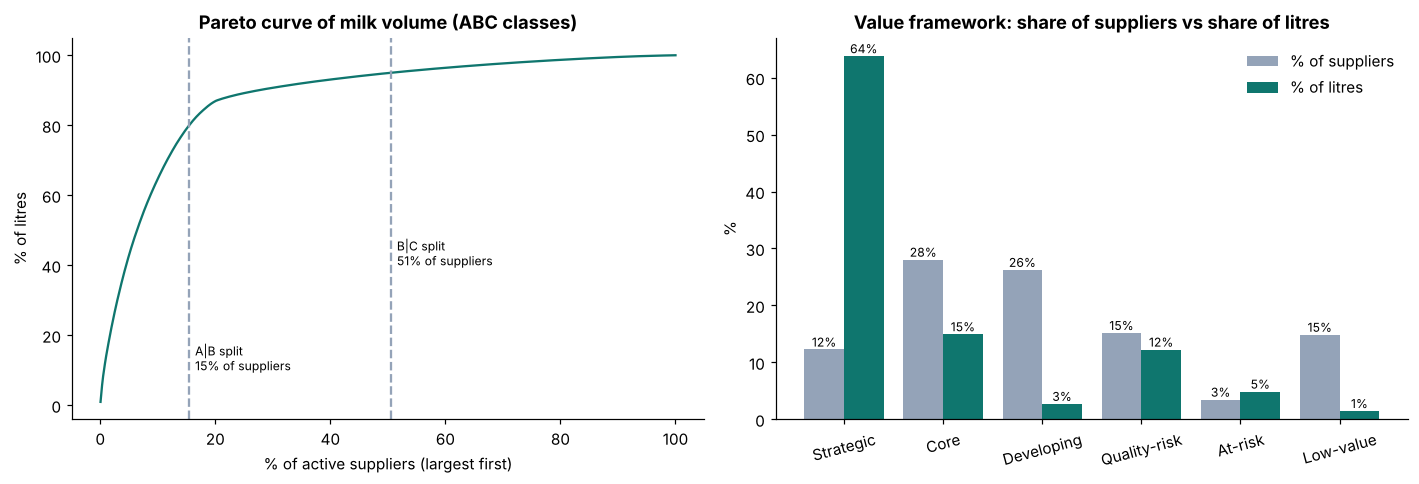

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
cum = S.litres_per_day_52w.cumsum().values / S.litres_per_day_52w.sum()
ax[0].plot(np.arange(1, len(S) + 1) / len(S) * 100, cum * 100, color=TEAL)
for lvl, lab in ((.80, "A"), (.95, "B")):
    n_ = int((cum_before < lvl).sum())
    ax[0].axvline(n_ / len(S) * 100, ls="--", color=GREY); ax[0].text(n_ / len(S) * 100 + 1, 10 + 30 * (lab == "B"), f"{lab}|{chr(ord(lab)+1)} split\n{n_ / len(S):.0%} of suppliers", fontsize=8)
ax[0].set(xlabel="% of active suppliers (largest first)", ylabel="% of litres", title="Pareto curve of milk volume (ABC classes)")
x = np.arange(len(vs))
ax[1].bar(x - .2, vs.supplier_share * 100, .4, color=GREY, label="% of suppliers")
ax[1].bar(x + .2, vs.litres_share * 100, .4, color=TEAL, label="% of litres")
ax[1].set_xticks(x, vs.index, rotation=15); ax[1].legend(frameon=False)
for i, (a, b) in enumerate(zip(vs.supplier_share, vs.litres_share)):
    ax[1].text(i - .2, a * 100, f"{a:.0%}", ha="center", va="bottom", fontsize=8); ax[1].text(i + .2, b * 100, f"{b:.0%}", ha="center", va="bottom", fontsize=8)
ax[1].set(ylabel="%", title="Value framework: share of suppliers vs share of litres")
fig.tight_layout(); fig.savefig(OUT / "02_value_framework.png", dpi=150); plt.show()

**Interpretation:**

* **The Pareto curve is steep.** Just **345 suppliers (15%)** deliver 80% of the milk: every one is a cooperative or commercial farm. The **1,102 smallest suppliers (49%)**, all smallholders, deliver only 5%.
* **Strategic: 273 suppliers (12%) carry 64% of all litres.** They are the backbone of supply, and they deliver on a median 93% of days with a rejection rate below 1%. Losing even a few of them in the dry season would be felt at the plant.
* **Core: 625 suppliers (28%), 15% of litres.** Mostly larger smallholders (84%) plus some less consistent bulk suppliers.
* **Developing: 585 smallholders (26%), 3% of litres.** Small but dependable (95% of days delivered). These are the farmers to grow through extension, AI services and feed credit.
* **Quality-risk: 338 suppliers (15%), 12% of litres**, with an average rejection rate of **5.0%**, about seven times that of the clean segments. This segment includes **43 bulk suppliers**. An antibiotic-positive delivery from a 1,000-litre supplier can condemn a whole tanker, so these suppliers matter far beyond their own volume.
* **At-risk: 77 suppliers (3.5%), 4.9% of litres**, already fading (median season-adjusted trend 0.70). Part B shows whether this simple flag really predicts churn.
* **Low-value: 331 smallholders (15%), 1.5% of litres**, small and erratic. Serve them at the lowest possible cost.

## 6. K-means clustering — letting the data define the segments

The framework above encodes what a milk-procurement manager *already believes* matters. **K-means** asks a different question: *if we only give the algorithm supplier behaviour, which natural groups appear?* If its groups match the framework, both gain credibility. If they differ, we learn something.

### Preparing the data

Seven behavioural features, chosen to cover volume, consistency, trend and quality:

* `log_litres_per_day`: **log**-transformed, because volume spans more than three orders of magnitude (a 3 L/day smallholder vs a 2,000 L/day cooperative). Without the log, a few big cooperatives would dominate every distance calculation.
* `delivery_day_share`, `log_cv` (log of CV + 0.05, to tame a long right tail), `log_trend`
* `fat_pct`, `snf_pct`, `log_rejection` (log of 1 + rejection % for the same reason)

Each feature is then **standardised** (mean 0, SD 1) so that each counts equally in the distance calculation.

In [8]:
cluster_features = pd.DataFrame({
    "log_litres_per_day": np.log1p(S.litres_per_day_52w), "delivery_day_share": S.delivery_day_share_13w,
    "log_cv": np.log(S.litres_cv_26w + .05), "log_trend": np.log(S.litres_trend),
    "fat_pct": S.fat_pct, "snf_pct": S.snf_pct, "log_rejection": np.log1p(100 * S.rejection_rate)}, index=S.index)
Zs = StandardScaler().fit_transform(cluster_features)
cluster_features.describe().round(2)

,log_litres_per_day,delivery_day_share,log_cv,log_trend,fat_pct,snf_pct,log_rejection
count,2229.00,2229.00,2229.00,2229.00,2229.00,2229.00,2229.00
mean,3.54,0.90,-1.26,-0.04,3.80,8.55,0.62
std,1.40,0.10,0.31,0.18,0.24,0.14,0.66
min,1.38,0.33,-3.00,-1.61,3.08,7.95,0.00
25%,2.63,0.87,-1.40,-0.12,3.63,8.45,0.00
50%,3.08,0.92,-1.28,-0.01,3.81,8.54,0.49
75%,3.79,0.97,-1.16,0.07,3.97,8.64,1.12
max,7.88,1.00,0.58,0.63,4.59,9.00,3.00


### How many clusters? Elbow and silhouette

* **Elbow (inertia):** within-cluster sum of squares always falls as *k* grows. We look for the point where extra clusters stop helping much.
* **Silhouette score** (−1 to 1): how well each supplier fits its own cluster compared with the nearest other cluster. Higher is better.

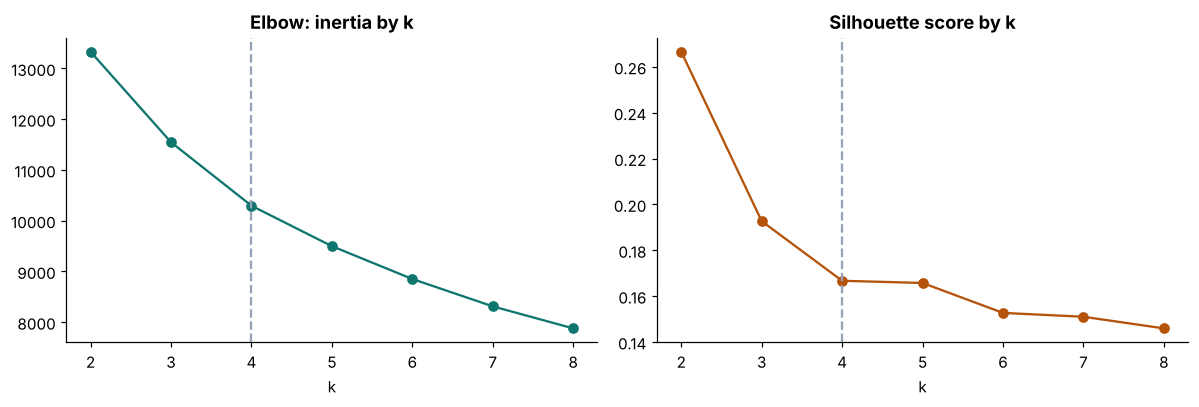

,inertia,silhouette
2,13328.823,0.267
3,11545.756,0.193
4,10294.646,0.167
5,9497.838,0.166
6,8850.902,0.153
7,8311.774,0.151
8,7877.707,0.146


In [9]:
ks = range(2, 9)
fits = {k: KMeans(k, n_init=20, random_state=42).fit(Zs) for k in ks}
sel = pd.DataFrame({"inertia": [fits[k].inertia_ for k in ks],
                    "silhouette": [silhouette_score(Zs, fits[k].labels_) for k in ks]}, index=ks)
K = 4
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(sel.index, sel.inertia, "o-", color=TEAL); ax[0].set(title="Elbow: inertia by k", xlabel="k")
ax[1].plot(sel.index, sel.silhouette, "o-", color=AMBER); ax[1].set(title="Silhouette score by k", xlabel="k")
for a in ax: a.axvline(K, ls="--", color=GREY)
fig.tight_layout(); fig.savefig(OUT / "03_choose_k.png", dpi=150); plt.show()
sel.round(3)

**Interpretation:** the silhouette score is highest at **k = 2** (0.27). That split is simply *bulk suppliers vs smallholders*, which we already know from the supplier type, so it adds nothing new. The score drops to 0.19 at k = 3 and then flattens (0.167 at k = 4, 0.166 at k = 5). The elbow curve also loses its steepest gains after k = 4. **We choose k = 4**: it is the last k before the silhouette plateau, and (as the profiles show) each of the four groups calls for a different action. Larger *k* mostly splits smallholders by fat and SNF, which reflects breed and isn't something a field officer can act on.

Silhouette values around 0.17 mean the clusters **overlap**. Supplier behaviour is a continuum, not a set of islands. That's normal for behavioural data. The clusters are still useful as *descriptions*, but borderline suppliers could reasonably sit in a neighbouring cluster.

In [10]:
km = fits[K]
S["cluster_id"] = km.labels_
zc = pd.DataFrame(Zs, columns=cluster_features.columns, index=S.index).groupby(S.cluster_id).mean()

# Name clusters from their profile (robust to K-means label order):
#   largest volume -> bulk; of the rest, lowest delivery-day share -> erratic/fading;
#   of the remaining two, higher rejection -> quality issues, lower -> steady & clean
names = {}
bulk = zc.log_litres_per_day.idxmax(); names[bulk] = "Bulk suppliers"
rest = zc.drop(bulk)
erratic = rest.delivery_day_share.idxmin(); names[erratic] = "Erratic / fading smallholders"
rest = rest.drop(erratic)
names[rest.log_rejection.idxmax()] = "Smallholders with quality issues"
names[rest.log_rejection.idxmin()] = "Steady clean smallholders"
S["cluster"] = S.cluster_id.map(names)
CSEG = ["Bulk suppliers", "Steady clean smallholders", "Smallholders with quality issues", "Erratic / fading smallholders"]

prof = S.groupby("cluster").agg(suppliers=("supplier_id", "size"), median_litres_day=("litres_per_day_52w", "median"),
                                delivery_day_share=("delivery_day_share_13w", "median"), weekly_cv=("litres_cv_26w", "median"),
                                median_trend=("litres_trend", "median"), fat_pct=("fat_pct", "mean"), snf_pct=("snf_pct", "mean"),
                                rejection_rate=("rejection_rate", "mean"), litres_per_day=("litres_per_day_52w", "sum")).reindex(CSEG)
prof["litres_share"] = prof.litres_per_day / prof.litres_per_day.sum()
prof.round(3)

,suppliers,median_litres_day,delivery_day_share,weekly_cv,median_trend,fat_pct,snf_pct,rejection_rate,litres_per_day,litres_share
cluster,,,,,,,,,,
Bulk suppliers,430,443.669,0.934,0.225,0.994,3.703,8.545,0.011,237186.735,0.851
Steady clean smallholders,909,17.827,0.934,0.220,0.983,3.819,8.559,0.002,19685.829,0.071
Smallholders with quality issues,690,17.545,0.923,0.229,1.008,3.851,8.529,0.031,16507.449,0.059
Erratic / fading smallholders,200,13.638,0.703,0.431,0.782,3.774,8.545,0.013,5319.105,0.019


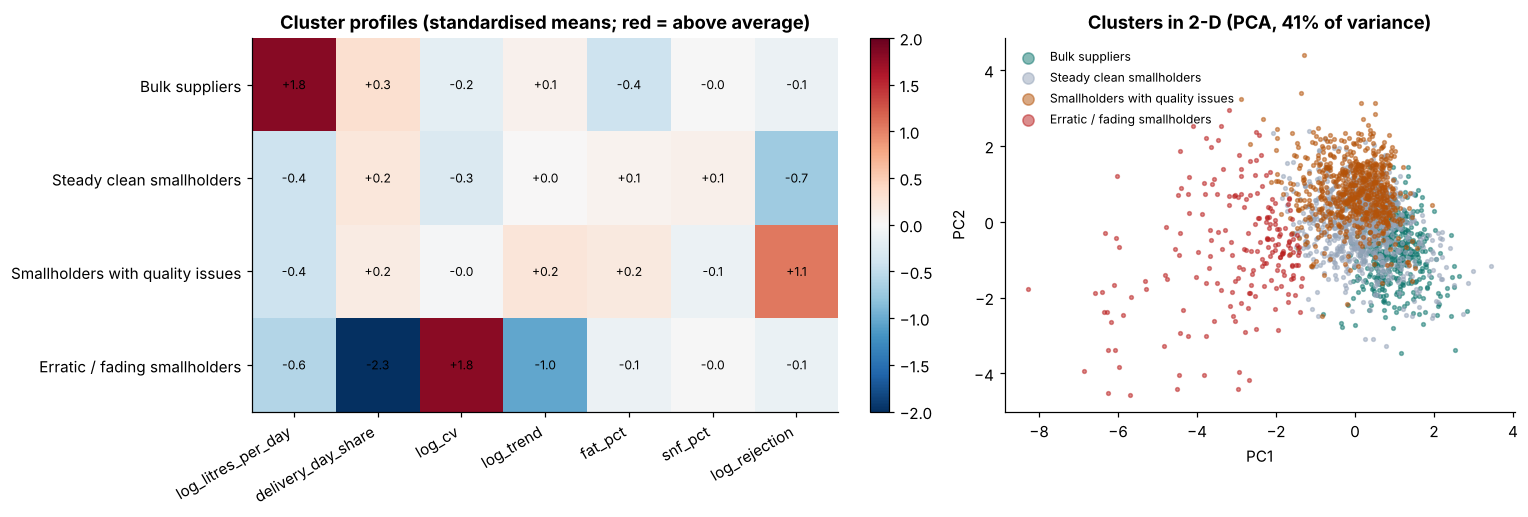

supplier_type,Commercial farm,Farmer group/cooperative,Smallholder
cluster,,,
Bulk suppliers,211,214,5
Steady clean smallholders,4,0,905
Smallholders with quality issues,8,5,677
Erratic / fading smallholders,5,0,195


In [11]:
z = zc.rename(index=names).loc[CSEG]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1.25, 1]})
im = ax[0].imshow(z.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax[0].set_xticks(range(z.shape[1]), z.columns, rotation=30, ha="right"); ax[0].set_yticks(range(len(z)), z.index)
for i in range(z.shape[0]):
    for j in range(z.shape[1]):
        ax[0].text(j, i, f"{z.values[i, j]:+.1f}", ha="center", va="center", fontsize=8)
ax[0].set_title("Cluster profiles (standardised means; red = above average)")
plt.colorbar(im, ax=ax[0], fraction=.03)
pcs = PCA(2, random_state=0).fit(Zs); P = pcs.transform(Zs)
for name, c in zip(CSEG, [TEAL, GREY, AMBER, RED]):
    mk = (S.cluster == name).values
    ax[1].scatter(P[mk, 0], P[mk, 1], s=6, alpha=.5, color=c, label=name)
ax[1].set(title=f"Clusters in 2-D (PCA, {pcs.explained_variance_ratio_.sum():.0%} of variance)", xlabel="PC1", ylabel="PC2")
ax[1].legend(frameon=False, markerscale=3, fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "04_cluster_profiles.png", dpi=150); plt.show()
pd.crosstab(S.cluster, S.supplier_type).loc[CSEG]

**Interpretation, the four behavioural clusters:**

| Cluster | Suppliers | What the data says | Share of litres |
|---|---:|---|---:|
| **Bulk suppliers** | 430 | Cooperatives and commercial farms (all but 5); median 444 L/day; deliver on 93% of days; slightly lower fat (commercial Friesian herds) | **85%** |
| **Steady clean smallholders** | 909 | Median 18 L/day, very low rejections (0.2%) and steady weekly volume | 7% |
| **Smallholders with quality issues** | 690 | Same size and consistency as the steady group, but an average rejection rate of **3.1%** | 6% |
| **Erratic / fading smallholders** | 200 | 195 smallholders plus 5 commercial farms whose volume is collapsing (the name follows the majority; those 5 farms top the action list). Deliver on only 70% of days; weekly CV 0.43 (about twice the others); season-adjusted trend 0.78 | 2% |

The heatmap shows what separates the groups. **Volume** sets the bulk cluster apart (+1.8 SD). **Rejections** split the two mainstream smallholder groups (+1.1 vs −0.7 SD). **Delivery-day share, volatility and trend** pick out the erratic group (−2.3, +1.8 and −1.0 SD). In the PCA plot, bulk suppliers sit to the right and erratic smallholders spread out to the left. The two mainstream smallholder clusters overlap heavily in two dimensions, which matches the modest silhouette.

In [12]:
pd.crosstab(S.value_segment, S.cluster).reindex(VSEG)[CSEG]

cluster,Bulk suppliers,Steady clean smallholders,Smallholders with quality issues,Erratic / fading smallholders
value_segment,,,,
Strategic,272,0,1,0
Core,98,343,167,17
Developing,0,412,173,0
Quality-risk,43,0,266,29
At-risk,17,23,14,23
Low-value,0,131,69,131


**Framework vs K-means:** the two methods agree where it matters, and they add to each other.

* **272 of the 273 Strategic suppliers** sit in the *Bulk* cluster. The rule-based framework and the algorithm agree on who the backbone is.
* Most **Quality-risk** suppliers (266 of 338) sit in *Smallholders with quality issues*. The framework also flags **43 bulk suppliers** whose rejection rate is ≥ 3%. K-means puts them in the bulk cluster because volume dominates their profile. The framework catches them because quality is a hard rule.
* **At-risk** suppliers are spread across all four clusters. Fading is a *state* that any supplier can enter, not a type of supplier. That is why a churn model (Part B) is needed on top of segmentation.

In practice: **K-means describes the supply base; the framework assigns the actions**, because its rules are transparent and fixed, so a field officer can explain why a farmer is in a segment.

## 7. The supply-strategy matrix (2 × 2)

Managers need a picture they can act on. Supply risk and supply value are two different things, which gives a classic **2 × 2 matrix** (in the spirit of Kraljic's purchasing portfolio):

* **x-axis, volume:** litres per day (log scale). The dividing line is the **A/B threshold**: the smallest supplier inside the top 80% of volume.
* **y-axis, reliability:** a 0–1 score = delivery-day share × (1 − min(CV, 1)). It is high when milk arrives every day in steady amounts.
* Dividing line for reliability: the **median** supplier.
* Colour: **quality-risk** suppliers (rejection ≥ 3%) are shown in red.

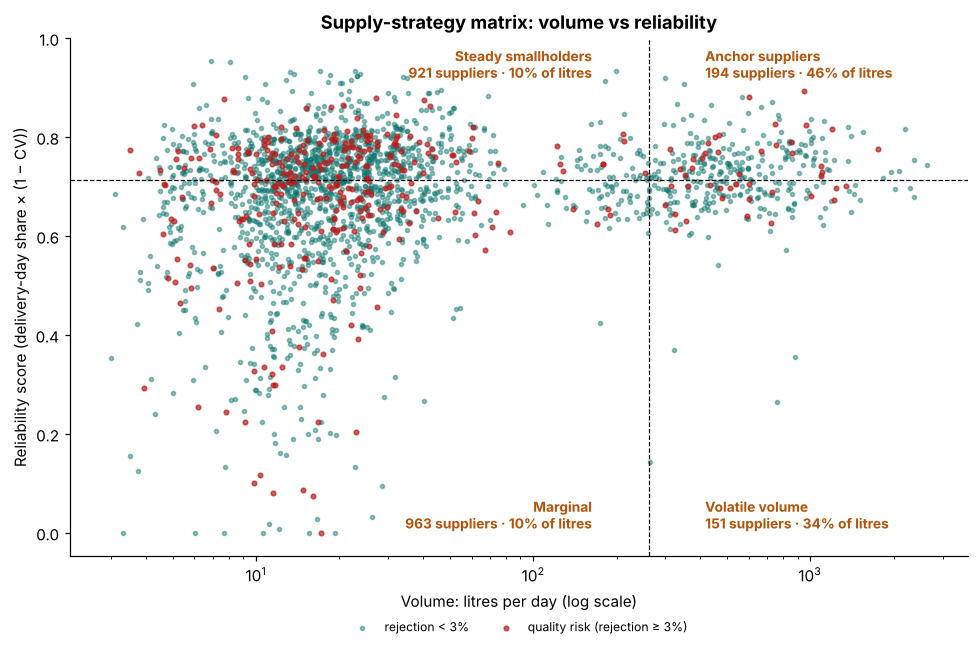

Volume line = 261 L/day | reliability line (median) = 0.71


,n,litres,share,quality_risk_share
quadrant,,,,
Anchor suppliers,194,129341.290,0.464,0.129
Marginal,963,27032.415,0.097,0.166
Steady smallholders,921,28616.690,0.103,0.163
Volatile volume,151,93708.723,0.336,0.132


In [13]:
S["reliability"] = S.delivery_day_share_13w * (1 - S.litres_cv_26w.clip(upper=1))
v_cut = S.loc[S.abc_class == "A", "litres_per_day_52w"].min()
r_cut = S.reliability.median()
S["quadrant"] = np.select([(S.litres_per_day_52w >= v_cut) & (S.reliability >= r_cut),
                           (S.litres_per_day_52w >= v_cut) & (S.reliability < r_cut),
                           (S.litres_per_day_52w < v_cut) & (S.reliability >= r_cut)],
                          ["Anchor suppliers", "Volatile volume", "Steady smallholders"], "Marginal")
fig, ax = plt.subplots(figsize=(9, 6))
q = S.quality_risk.values
ax.scatter(S.litres_per_day_52w[~q], S.reliability[~q], s=7, alpha=.45, color=TEAL, label="rejection < 3%")
ax.scatter(S.litres_per_day_52w[q], S.reliability[q], s=9, alpha=.7, color=RED, label="quality risk (rejection ≥ 3%)")
ax.set_xscale("log"); ax.axvline(v_cut, color="black", lw=.8, ls="--"); ax.axhline(r_cut, color="black", lw=.8, ls="--")
quad = S.groupby("quadrant").agg(n=("supplier_id", "size"), litres=("litres_per_day_52w", "sum"))
quad["share"] = quad.litres / quad.litres.sum()
xl, yl = ax.get_xlim(), ax.get_ylim()
pos = {"Anchor suppliers": (v_cut * 1.6, yl[1] - .02, "left"), "Volatile volume": (v_cut * 1.6, yl[0] + .05, "left"),
       "Steady smallholders": (v_cut / 1.6, yl[1] - .02, "right"), "Marginal": (v_cut / 1.6, yl[0] + .05, "right")}
for name, (xx, yy, ha) in pos.items():
    ax.text(xx, yy, f"{name}\n{quad.n[name]:,} suppliers · {quad.share[name]:.0%} of litres", ha=ha, va="top" if yy > .5 else "bottom",
            fontsize=9, fontweight="bold", color=AMBER)
ax.set(xlabel="Volume: litres per day (log scale)", ylabel="Reliability score (delivery-day share × (1 − CV))",
       title="Supply-strategy matrix: volume vs reliability")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(.5, -.1), ncol=2, fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "05_supply_strategy_matrix.png", dpi=150); plt.show()
print(f"Volume line = {v_cut:,.0f} L/day | reliability line (median) = {r_cut:.2f}")
quad.assign(quality_risk_share=S.groupby("quadrant").quality_risk.mean()).round(3)

**Interpretation, the four quadrants:**

| Quadrant | Suppliers | Litres | Strategy |
|---|---:|---:|---|
| **Anchor suppliers**: high volume, high reliability | 194 | **46%** | Protect: key-account style relationship, fastest payment, first call on price reviews |
| **Volatile volume**: high volume, lower reliability | 151 | **34%** | Secure: supply agreements, collection-time flexibility, find out why volumes swing |
| **Steady smallholders**: low volume, high reliability | 921 | 10% | Develop: extension, AI, feed credit to grow yield per cow |
| **Marginal**: low volume, low reliability | 963 | 10% | Serve efficiently: group collection, digital payments, minimal field time |

Two honest observations:

* Among bulk suppliers, reliability varies over a **narrow band** (mostly 0.6–0.85), because large farms rarely miss a day. "Volatile volume" therefore means *less steady than the median*, not chaotic. The genuinely erratic suppliers are smallholders in the lower-left corner.
* **Quality risk is spread across all four quadrants** (13–17% of suppliers in each). Quality problems have nothing to do with size, so quality training can't be limited to small farmers.

---
# PART B — SUPPLIER CHURN ANALYSIS

## 8. Define churn and measure it

**Population:** the active suppliers segmented above (delivered in the 4 weeks to 28 June 2026).
**Churn = 1** if the supplier makes **no delivery between 27 July and 27 September 2026**: they stop within about four weeks of the snapshot and stay silent for 63+ days, through the heart of the dry season.

In [14]:
A = S.copy()
A["churned"] = churn_label(dl)(A.supplier_id)
print(f"Active suppliers: {len(A):,} | churned: {A.churned.sum()} ({A.churned.mean():.1%}) | "
      f"litres/day of churners (last 12 months): {A.loc[A.churned == 1, 'litres_per_day_52w'].sum():,.0f} "
      f"({A.loc[A.churned == 1, 'litres_per_day_52w'].sum() / A.litres_per_day_52w.sum():.1%} of volume)")
A.groupby("supplier_type").agg(suppliers=("supplier_id", "size"), churn_rate=("churned", "mean"),
                               litres_lost_per_day=("litres_per_day_52w", lambda s: s[A.loc[s.index, "churned"] == 1].sum())).round(3)

Active suppliers: 2,229 | churned: 254 (11.4%) | litres/day of churners (last 12 months): 21,621 (7.8% of volume)


,suppliers,churn_rate,litres_lost_per_day
supplier_type,,,
Commercial farm,228,0.132,13363.463
Farmer group/cooperative,219,0.032,4080.227
Smallholder,1782,0.122,4177.562


**Interpretation:** **254 of 2,229 active suppliers (11.4%)** stopped delivering within a month of the snapshot and stayed away through the dry season. Together they had been delivering about **21,600 litres/day, 7.8% of volume**.

* **Commercial farms churn as often as smallholders** (13.2% vs 12.2%), and because each one is large they account for **62% of the litres lost** (13,400 of 21,600 L/day). Farmer groups / cooperatives churn far less (3.2%).
* As in any churn problem, the positive class is the *minority*. A model that predicts "nobody churns" would be about 89% accurate and completely useless, so we evaluate with **AUC, precision / recall and lift**.

## 9. Exploratory analysis — what do churners look like?

Each panel compares the churn rate across groups of a single driver. The dashed line is the overall churn rate.

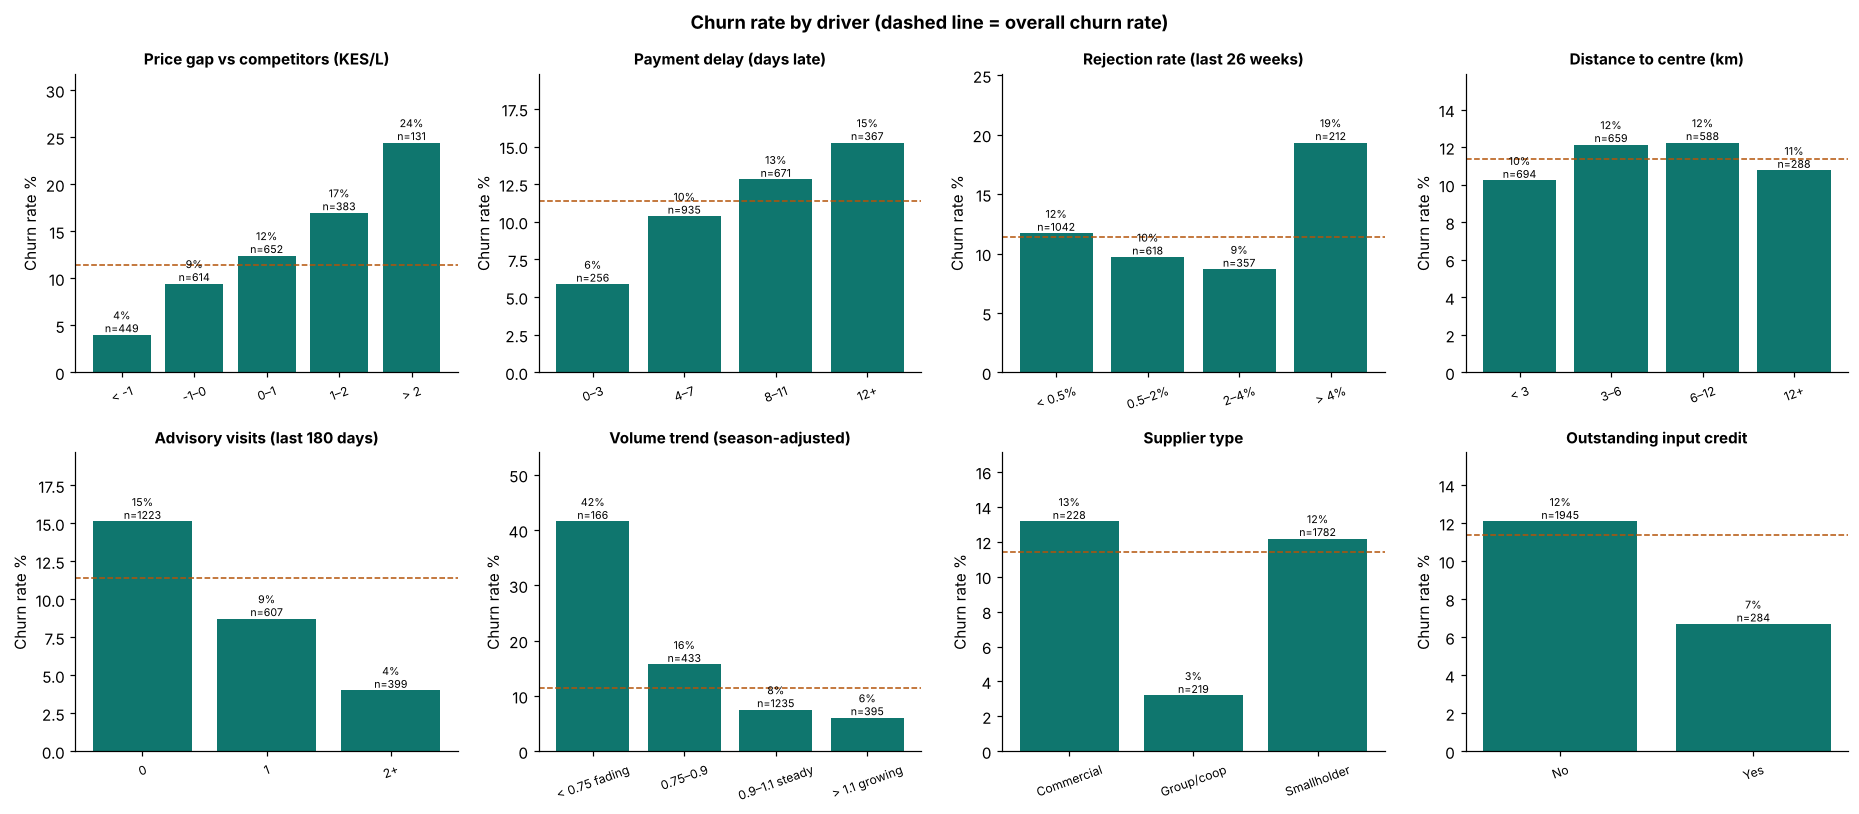

churn_rate  suppliers
Price gap vs competitors (KES/L) < -1                 0.040        449
                                 -1–0                 0.094        614
                                 0–1                  0.124        652
                                 1–2                  0.170        383
                                 > 2                  0.244        131
Payment delay (days late)        0–3                  0.059        256
                                 4–7                  0.104        935
                                 8–11                 0.128        671
                                 12+                  0.153        367
Rejection rate (last 26 weeks)   < 0.5%               0.117       1042
                                 0.5–2%               0.097        618
                                 2–4%                 0.087        357
                                 > 4%                 0.193        212
Distance to centre (km)          < 3                  0.102        694
                                 3–6                  0.121        659
                                 6–12                 0.122        588
                                 12+                  0.108        288
Advisory visits (last 180 days)  0                    0.151       1223
                                 1                    0.087        607
                                 2+                   0.040        399
Volume trend (season-adjusted)   < 0.75 fading        0.416        166
                                 0.75–0.9             0.157        433
                                 0.9–1.1 steady       0.075       1235
                                 > 1.1 growing        0.061        395
Supplier type                    Commercial           0.132        228
                                 Group/coop           0.032        219
                                 Smallholder          0.122       1782
Outstanding input credit         No                   0.121       1945
                                 Yes                  0.067        284

churn_rate  suppliers
Group member            0            0.132       1231
                        1            0.091        998
Quality training (180d) 0            0.128       1616
                        1+           0.077        613
Payment method          Bank         0.117        605
                        M-Pesa       0.113       1624

median_tenure_months  bulk_supplier_share  avg_visits  avg_price_gap
by rejection band < 0.5%                 10.90                 0.21        0.66           0.06
                  0.5–2%                 25.70                 0.20        0.89           0.04
                  2–4%                   16.50                 0.20        0.80          -0.04
                  > 4%                   16.30                 0.15        0.61           0.22
by distance band  < 3                    15.70                 0.02        0.63           0.15
                  3–6                    13.90                 0.08        0.70           0.18
                  6–12                   14.50                 0.26        0.76           0.06
                  12+                    17.05                 0.78        1.08          -0.47

In [15]:
def rate_by(col, bins=None, labels=None):
    g = pd.cut(A[col], bins, labels=labels) if bins is not None else A[col]
    return A.groupby(g, observed=True).churned.agg(["mean", "size"]).rename(columns={"mean": "churn_rate", "size": "suppliers"})

panels = {
    "Price gap vs competitors (KES/L)": rate_by("price_gap_kes", [-99, -1, 0, 1, 2, 99], ["< -1", "-1–0", "0–1", "1–2", "> 2"]),
    "Payment delay (days late)": rate_by("payment_delay_days", [-1, 3, 7, 11, 99], ["0–3", "4–7", "8–11", "12+"]),
    "Rejection rate (last 26 weeks)": rate_by("rejection_rate", [-.01, .005, .02, .04, 1], ["< 0.5%", "0.5–2%", "2–4%", "> 4%"]),
    "Distance to centre (km)": rate_by("distance_km", [0, 3, 6, 12, 99], ["< 3", "3–6", "6–12", "12+"]),
    "Advisory visits (last 180 days)": rate_by("advisory_visits_180d", [-1, 0, 1, 99], ["0", "1", "2+"]),
    "Volume trend (season-adjusted)": rate_by("litres_trend", [0, .75, .9, 1.1, 99], ["< 0.75 fading", "0.75–0.9", "0.9–1.1 steady", "> 1.1 growing"]),
    "Supplier type": rate_by("supplier_type").rename(index={"Farmer group/cooperative": "Group/coop", "Commercial farm": "Commercial"}),
    "Outstanding input credit": rate_by("has_credit").rename(index={0: "No", 1: "Yes"}),
}
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for ax, (title, t) in zip(axes.flat, panels.items()):
    ax.bar(t.index.astype(str), t.churn_rate * 100, color=TEAL)
    ax.axhline(A.churned.mean() * 100, ls="--", color=AMBER, lw=1)
    ax.set_title(title, fontsize=10); ax.set_ylabel("Churn rate %"); ax.tick_params(axis="x", rotation=20, labelsize=8)
    for i, (r, n_) in enumerate(zip(t.churn_rate, t.suppliers)):
        ax.text(i, r * 100, f"{r:.0%}\nn={n_}", ha="center", va="bottom", fontsize=7)
    ax.set_ylim(0, max(t.churn_rate * 100) * 1.3)
fig.suptitle("Churn rate by driver (dashed line = overall churn rate)", fontweight="bold")
fig.tight_layout(); fig.savefig(OUT / "06_churn_drivers_eda.png", dpi=150); plt.show()
display(pd.concat(panels).round(3))
extra = pd.concat({"Group member": rate_by("group_member"), "Quality training (180d)": rate_by("quality_training_180d", [-1, 0, 99], ["0", "1+"]),
                   "Payment method": rate_by("payment_method")})
display(extra.round(3))
A.assign(rej_band=pd.cut(A.rejection_rate, [-.01, .005, .02, .04, 1], labels=["< 0.5%", "0.5–2%", "2–4%", "> 4%"]),
         dist_band=pd.cut(A.distance_km, [0, 3, 6, 12, 99], labels=["< 3", "3–6", "6–12", "12+"])) \
 .pipe(lambda d: pd.concat({"by rejection band": d.groupby("rej_band", observed=True).agg(median_tenure_months=("tenure_months", "median"),
                                                     bulk_supplier_share=("supplier_type", lambda x: (x != "Smallholder").mean()), avg_visits=("advisory_visits_180d", "mean"),
                                                     avg_price_gap=("price_gap_kes", "mean")),
                            "by distance band": d.groupby("dist_band", observed=True).agg(median_tenure_months=("tenure_months", "median"),
                                                     bulk_supplier_share=("supplier_type", lambda x: (x != "Smallholder").mean()), avg_visits=("advisory_visits_180d", "mean"),
                                                     avg_price_gap=("price_gap_kes", "mean"))})).round(2)

**Interpretation:**

* **Price gap: the clearest gradient.** Suppliers whose realised price is more than KES 1/L *above* the competitor price churn at **4%**. Where competitors pay more than KES 2/L above our price, churn is **24%**, six times higher.
* **Payment delay:** churn rises steadily from **6%** (paid within 3 days of the due date) to **15%** (12+ days late). Farmers live on their milk cheque; a late payment pushes them towards brokers who pay cash.
* **Advisory visits:** **15%** churn with no extension or vet visit in 6 months, **9%** with one and **4%** with two or more.
* **Volume trend:** suppliers already fading (season-adjusted trend < 0.75) churn at **42%**, against 6–8% for steady or growing ones. Side-selling usually starts **partially**, which is exactly why churn can be predicted.
* **Input credit, group membership and quality training** all go with lower churn (7% vs 12%, 9% vs 13%, 8% vs 13%). The model below tests whether these effects hold up once the other drivers are controlled for.
* **Payment method** makes no difference (bank 11.7% vs M-Pesa 11.3%).

Two panels **don't show the expected pattern**, and both are confounding:

* **Rejection rate is U-shaped:** 12% churn at < 0.5% rejections, 9–10% in the middle bands, then **19%** above 4%. The cleanest band is dominated by **newer suppliers** (median tenure 10.9 months vs 16–26 months elsewhere). They have had fewer weeks to collect a rejection, and new suppliers churn more for other reasons. This is an **exposure effect**: a low rejection rate partly reflects *a short history*, not only clean milk. Only the > 4% band shows the true effect.
* **Distance looks flat** (10–12% in every band), even though longer trips should hurt. The **12+ km band is 78% bulk suppliers** (cooperatives and commercial farms that run their own transport) and has a *negative* average price gap (−0.47) because of volume bonuses. Their advantages hide the distance effect in a simple comparison.

Univariate views can mislead when drivers overlap. The logistic regression below estimates each driver's effect **holding the others constant**.

## 10. Prepare the modelling data

* **Features:** the behavioural, price, service and attribute variables from section 4.
  * **Fat and SNF are left out** of the churn model. They don't push farmers away directly. They act through the **quality bonus**, which is already inside `price_realised_kes` and therefore `price_gap_kes`. Including both would split one effect across correlated variables. They stay in the segmentation, where composition matters for its own sake.
  * `litres_per_day_52w` is replaced by `log_avg_daily_litres` (size on recent delivery days). Volume is heavily skewed, so it is logged.
  * **Centre and county dummies are left out on purpose.** The main ways a centre affects churn (its payment delays, the local competitor price and the distance farmers travel) are already measured directly. Adding centre dummies would absorb those effects and hide the operational levers we want to estimate.
* **Encoding:** supplier type becomes two dummies, `type_commercial` and `type_cooperative`. *Smallholder* is the reference category.
* **Split:** a deterministic **75 / 25 train / test split** (suppliers whose ID number is divisible by 4 go to test). The R script uses the identical split, so results can be compared exactly.
* **Scaling:** numeric features are standardised using **training-set** means and SDs only. Using test-set statistics would leak information about the test set into training.

In [16]:
A["log_avg_daily_litres"] = np.log1p(A.avg_daily_litres_13w)
A["log_litres_trend"] = np.log(A.litres_trend)
A["type_commercial"] = (A.supplier_type == "Commercial farm").astype(float)
A["type_cooperative"] = (A.supplier_type == "Farmer group/cooperative").astype(float)
FEATS = ["recency_days", "delivery_day_share_13w", "log_avg_daily_litres", "litres_cv_26w", "log_litres_trend",
         "rejection_rate", "price_gap_kes", "payment_delay_days", "distance_km", "advisory_visits_180d",
         "quality_training_180d", "has_credit", "group_member", "tenure_months", "pays_bank",
         "type_commercial", "type_cooperative"]
X = A[FEATS].astype(float)
y = A.churned.values
test = is_test(A.supplier_id).values
mu, sd = X[~test].mean(), X[~test].std()
Xs = (X - mu) / sd
print(f"Train: {(~test).sum():,} suppliers ({y[~test].mean():.1%} churn, {y[~test].sum()} churners) | "
      f"Test: {test.sum():,} suppliers ({y[test].mean():.1%} churn, {y[test].sum()} churners) | {X.shape[1]} features")

Train: 1,688 suppliers (11.3% churn, 190 churners) | Test: 541 suppliers (11.8% churn, 64 churners) | 17 features


## 11. Model 1 — Logistic regression (the explainable baseline)

Logistic regression models the **log-odds** of churn as a weighted sum of the features. Because the features are standardised, each coefficient shows the effect of a **one-standard-deviation** change. Exponentiating a coefficient gives an **odds ratio (OR)**:

* **OR > 1:** raises churn risk (OR 1.5 means 50% higher odds per 1 SD)
* **OR < 1:** protective

We fit it with `statsmodels` to get standard errors, 95% confidence intervals and p-values. The SD of each feature is printed alongside so that every OR can be translated back into business units.

In [17]:
logit = sm.Logit(y[~test], sm.add_constant(Xs[~test])).fit(disp=0)
ors = pd.DataFrame({"coef": logit.params, "odds_ratio": np.exp(logit.params),
                    "ci_low": np.exp(logit.conf_int()[0]), "ci_high": np.exp(logit.conf_int()[1]),
                    "p_value": logit.pvalues}).drop("const")
ors["sd_of_feature"] = sd
ors.to_csv(OUT / "logit_odds_ratios.csv")
p_lr = np.asarray(logit.predict(sm.add_constant(Xs[test])))
print(f"Pseudo-R² (McFadden): {logit.prsquared:.3f} | Test AUC: {roc_auc_score(y[test], p_lr):.3f}")
ors.sort_values("odds_ratio").round(3)

Pseudo-R² (McFadden): 0.229 | Test AUC: 0.796


,coef,odds_ratio,ci_low,ci_high,p_value,sd_of_feature
advisory_visits_180d,-0.481,0.618,0.473,0.808,0.000,1.073
quality_training_180d,-0.406,0.666,0.514,0.863,0.002,0.753
type_cooperative,-0.278,0.757,0.491,1.168,0.209,0.299
log_litres_trend,-0.249,0.779,0.642,0.946,0.012,0.186
log_avg_daily_litres,-0.151,0.860,0.563,1.314,0.485,1.376
group_member,-0.133,0.875,0.722,1.061,0.175,0.498
has_credit,-0.055,0.947,0.785,1.142,0.568,0.335
type_commercial,-0.042,0.959,0.674,1.364,0.816,0.302
delivery_day_share_13w,-0.016,0.984,0.773,1.252,0.894,0.096
tenure_months,0.030,1.031,0.850,1.250,0.759,34.580


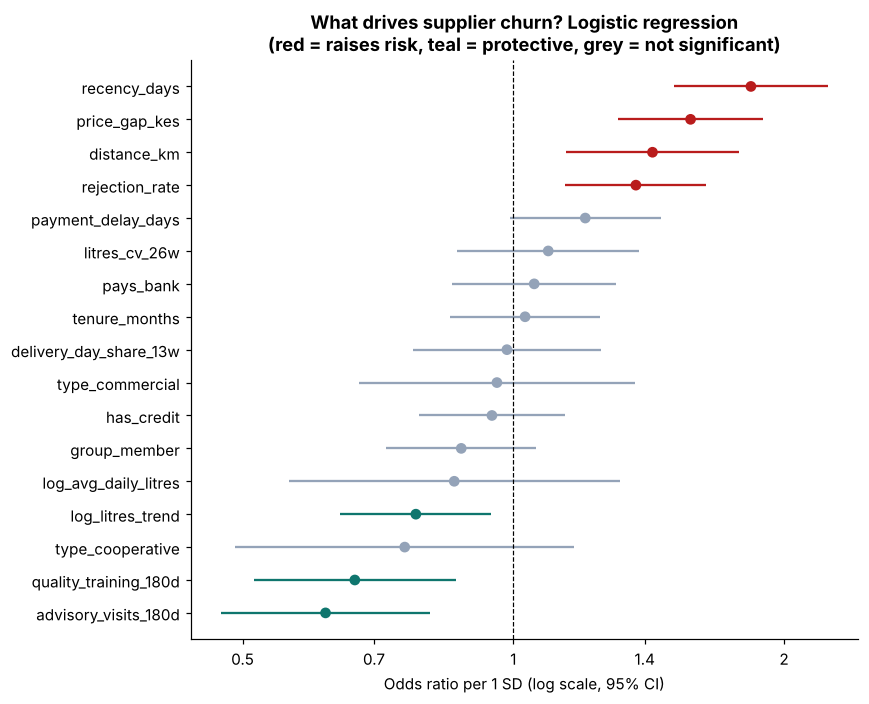

In [18]:
o = ors.sort_values("odds_ratio")
fig, ax = plt.subplots(figsize=(8, 6.5))
col = np.where(o.p_value < .05, np.where(o.odds_ratio > 1, RED, TEAL), GREY)
ax.errorbar(o.odds_ratio, range(len(o)), xerr=[o.odds_ratio - o.ci_low, o.ci_high - o.odds_ratio],
            fmt="none", ecolor=col, elinewidth=1.5)
ax.scatter(o.odds_ratio, range(len(o)), color=col, zorder=3)
ax.axvline(1, ls="--", color="black", lw=.8); ax.set_xscale("log")
ax.set_xticks([.5, .7, 1, 1.4, 2], ["0.5", "0.7", "1", "1.4", "2"]); ax.minorticks_off()
ax.set_yticks(range(len(o)), o.index)
ax.set(xlabel="Odds ratio per 1 SD (log scale, 95% CI)",
       title="What drives supplier churn? Logistic regression\n(red = raises risk, teal = protective, grey = not significant)")
fig.tight_layout(); fig.savefig(OUT / "07_odds_ratios.png", dpi=150); plt.show()

**Interpretation (each effect holds the other variables constant; sizes are per 1 SD, given in brackets):**

* **Price gap** (OR **1.57** per KES 1.25/L): the strongest *controllable* driver. Each extra KES 1.25 that competitors pay above our realised price raises the odds of losing the supplier by about 57%.
* **Recency** (OR **1.84** per 3 days): almost every active supplier delivered in the snapshot week, so in practice this measures *missing the last week or two*. It is an early sign of side-selling.
* **Distance** (OR **1.43** per 5.8 km): flat in the raw comparison, but clearly significant once supplier type, price and visits are controlled for. **The confounding in section 9 hid a real effect.**
* **Rejection rate** (OR **1.37** per 2 percentage points): rejections cost farmers money and goodwill. With tenure and the other drivers in the model, the exposure effect from section 9 no longer masks the risk.
* **Advisory visits** (OR **0.62** per ~1 visit) and **quality training** (OR **0.67** per 0.75 visits) are the strongest *protective* factors. Quality training is triggered *by* rejections, so the raw numbers mix two opposite effects. With the rejection rate held constant, training is clearly protective: **a rejected farmer who gets a visit is less likely to leave than one who gets only the rejection slip.**
* **Season-adjusted trend** (OR **0.78** per SD): fading suppliers are more likely to leave, even after recency is accounted for.
* **Payment delay** (OR **1.20** per 3.7 days, 95% CI 0.99–1.46, p = 0.06): raises risk, consistent with the clear gradient in section 9, but only borderline significant in this sample.
* **Not significant once the above are controlled for:** input credit (OR 0.95), group membership (0.88), supplier type, tenure, bank payment, volume and consistency. **Credit and group membership** looked protective in the raw data, but their holders also get more visits and better terms. In a sample with 190 training churners the model can't separate their independent effect from those overlaps. "Not significant" here means **not proven**, not **no effect**. The low churn of cooperatives is likewise explained by their price (volume bonus), visits and membership, not by being a cooperative as such.

Odds ratios show **association, not proof of causation**. Still, the significant controllable drivers (price gap, rejections, distance, visits and, borderline, payment speed) are exactly the levers a milk-procurement team can pull.

## 12. Models 2 & 3 — Random forest and gradient boosting

Tree ensembles capture **non-linear effects and interactions** automatically. For example, a price gap might hurt far-away farmers more than those next door to the centre. They often predict better, but they are harder to explain. We compare all three on the **same held-out test set**:

| Metric | Meaning |
|---|---|
| **ROC-AUC** | Probability that a random churner is scored higher than a random stayer (0.5 = coin flip, 1 = perfect) |
| **PR-AUC** (average precision) | How precise the model stays as it captures more churners. Informative when churn is rare (baseline = churn rate) |
| **Brier score** | Mean squared error of the probabilities (lower = better calibrated) |

In [19]:
rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=10, max_features=.5, random_state=0, n_jobs=-1).fit(X[~test], y[~test])
gb = GradientBoostingClassifier(n_estimators=200, learning_rate=.03, max_depth=2, subsample=.8, random_state=0).fit(X[~test], y[~test])
preds = {"Logistic regression": p_lr, "Random forest": rf.predict_proba(X[test])[:, 1],
         "Gradient boosting": gb.predict_proba(X[test])[:, 1]}
metrics = pd.DataFrame({m: {"ROC-AUC": roc_auc_score(y[test], p), "PR-AUC": average_precision_score(y[test], p),
                            "Brier": brier_score_loss(y[test], p)} for m, p in preds.items()}).T
metrics.loc["(baseline: no model)"] = [.5, y[test].mean(), brier_score_loss(y[test], np.full(test.sum(), y[~test].mean()))]
metrics.to_csv(OUT / "model_metrics.csv"); metrics.round(3)

,ROC-AUC,PR-AUC,Brier
Logistic regression,0.796,0.465,0.084
Random forest,0.780,0.475,0.083
Gradient boosting,0.760,0.429,0.085
(baseline: no model),0.500,0.118,0.104


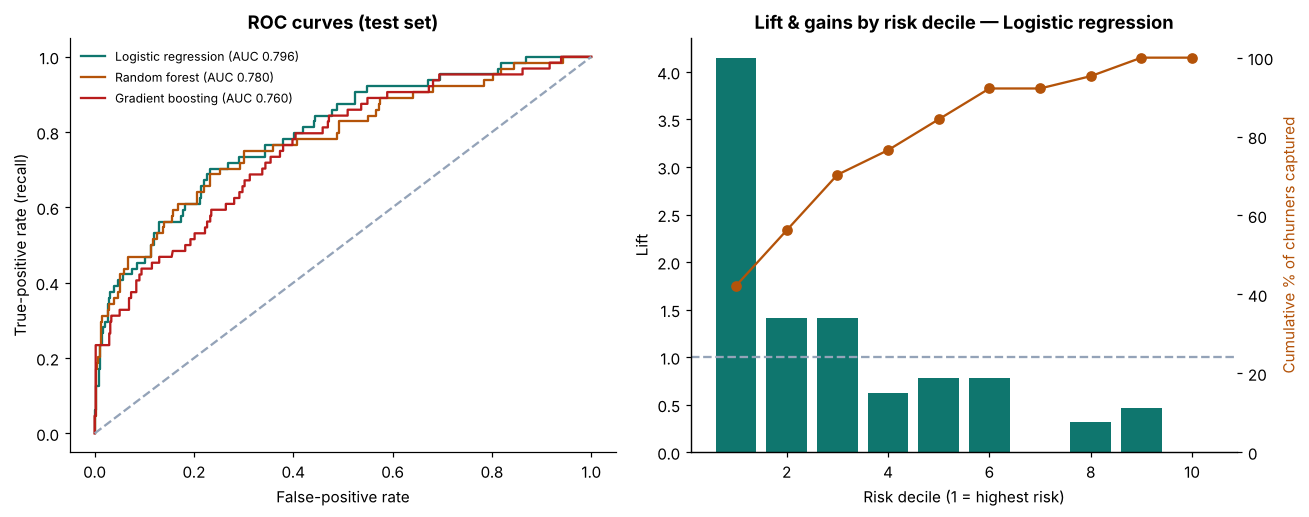

Best model by test ROC-AUC: Logistic regression


,sum,size,cum_capture,lift
decile,,,,
1,27,55,0.42,4.15
2,9,54,0.56,1.41
3,9,54,0.70,1.41
4,4,54,0.77,0.63
5,5,54,0.84,0.78
6,5,54,0.92,0.78
7,0,54,0.92,0.00
8,2,54,0.95,0.31
9,3,54,1.00,0.47


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
for (m_, p), c in zip(preds.items(), [TEAL, AMBER, RED]):
    fpr, tpr, _ = roc_curve(y[test], p)
    ax[0].plot(fpr, tpr, color=c, label=f"{m_} (AUC {roc_auc_score(y[test], p):.3f})")
ax[0].plot([0, 1], [0, 1], ls="--", color=GREY); ax[0].legend(frameon=False, fontsize=8)
ax[0].set(title="ROC curves (test set)", xlabel="False-positive rate", ylabel="True-positive rate (recall)")

best_name = metrics.drop("(baseline: no model)")["ROC-AUC"].idxmax()
p_best = preds[best_name]
dec = pd.qcut(pd.Series(p_best).rank(method="first", ascending=False), 10, labels=range(1, 11))
gains = pd.DataFrame({"y": y[test], "decile": dec.values}).groupby("decile", observed=True).y.agg(["sum", "size"])
gains["cum_capture"] = gains["sum"].cumsum() / gains["sum"].sum()
gains["lift"] = (gains["sum"] / gains["size"]) / y[test].mean()
ax[1].bar(gains.index.astype(int), gains.lift, color=TEAL)
ax[1].axhline(1, ls="--", color=GREY)
ax2 = ax[1].twinx(); ax2.plot(gains.index.astype(int), gains.cum_capture * 100, "o-", color=AMBER)
ax2.set_ylabel("Cumulative % of churners captured", color=AMBER); ax2.set_ylim(0, 105)
ax[1].set(title=f"Lift & gains by risk decile — {best_name}", xlabel="Risk decile (1 = highest risk)", ylabel="Lift")
fig.tight_layout(); fig.savefig(OUT / "08_roc_and_gains.png", dpi=150); plt.show()
print("Best model by test ROC-AUC:", best_name)
gains.round(2)

**Interpretation:**

* All three models are **clearly better than chance**: ROC-AUC 0.76–0.80 against 0.50, and PR-AUC 0.43–0.48 against a 0.12 baseline. These are realistic numbers for a behavioural churn problem. Some leavers stop abruptly for reasons no record captures (a family emergency, a broker's one-off offer).
* The **logistic regression is the best model** on ROC-AUC (0.796) and nearly ties on the Brier score (0.084 vs 0.083 for the random forest). The random forest has a slightly higher PR-AUC (0.475 vs 0.465). The flexible tree models don't beat the linear model, so the drivers act in a fairly **simple, monotonic** way. We don't have to give up explainability for accuracy, and we use the logistic regression for scoring.
* The **gains chart** is the business view. The riskiest **10%** of suppliers contain **42%** of future churners (lift 4.2×), the top 20% contain **56%** and the top 30% about **70%**. A short field list reaches most of the problem.
* The test set has only 64 churners, so these metrics carry noticeable sampling uncertainty (the Hanley–McNeil standard error of the logistic AUC is about 0.034, so its 95% interval runs from roughly 0.73 to 0.86).

In [21]:
thr = np.quantile(p_best, .80)                     # act on the riskiest 20% of suppliers
pred = (p_best >= thr).astype(int)
cm = pd.DataFrame(confusion_matrix(y[test], pred), index=["Actual: stayed", "Actual: churned"],
                  columns=["Predicted: stay", "Predicted: churn"])
print(f"Threshold = top 20% risk (p >= {thr:.2f}) | precision = {precision_score(y[test], pred):.0%} | "
      f"recall = {recall_score(y[test], pred):.0%}")
cm

Threshold = top 20% risk (p >= 0.14) | precision = 33% | recall = 56%


,Predicted: stay,Predicted: churn
Actual: stayed,404,73
Actual: churned,28,36


**How to read the confusion matrix:** if field officers visit the riskiest 20% of suppliers (probability ≥ 0.14), **one visit in three (33%) reaches a supplier who really was about to leave**, and the visits reach **56%** of all leavers. The other two-thirds of visits still go to suppliers who are above average risk and rarely wasted, because an advisory visit is itself protective. The cut-off is a **business choice**. Section 14 sets it on economics instead of a fixed percentage.

## 13. What do the tree models rely on? Permutation importance

**Permutation importance** shuffles one feature at a time on the test set and measures how much the AUC drops. A large drop means the model depends on that feature. Unlike built-in tree importances, it isn't biased towards continuous features with many distinct values. We compute it for the gradient-boosting model, a non-linear check on the logistic regression's story. Two caveats:

* With only about 60 churners in the test set, small importances are noisy, so we repeat each shuffle 30 times and show the spread.
* Correlated features can share importance.

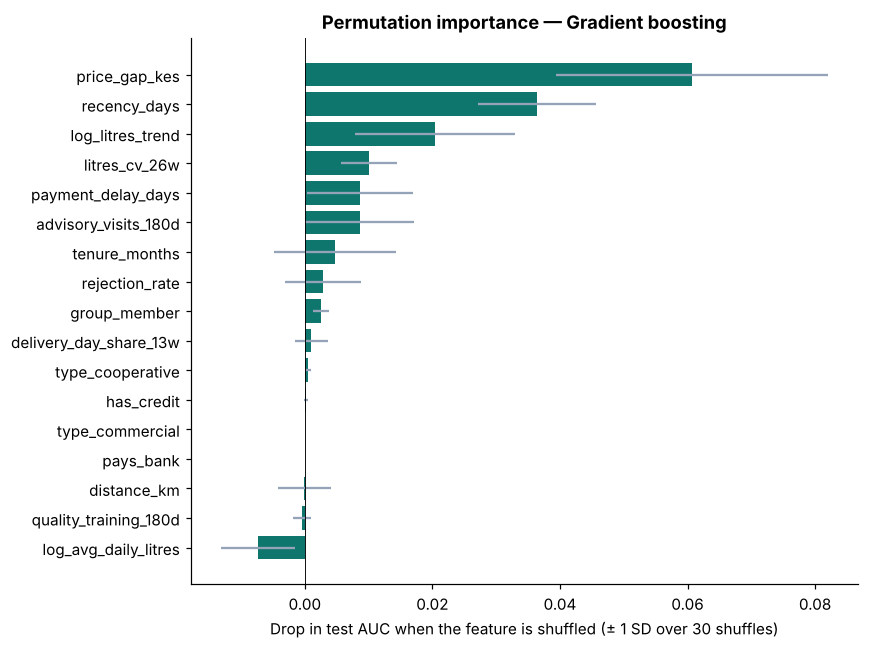

,mean,sd
price_gap_kes,0.0607,0.0213
recency_days,0.0364,0.0093
log_litres_trend,0.0204,0.0125
litres_cv_26w,0.0101,0.0044
payment_delay_days,0.0086,0.0084
advisory_visits_180d,0.0086,0.0086
tenure_months,0.0047,0.0095
rejection_rate,0.0028,0.0060


In [22]:
pi = permutation_importance(gb, X[test], y[test], scoring="roc_auc", n_repeats=30, random_state=0)
imp = pd.DataFrame({"mean": pi.importances_mean, "sd": pi.importances_std}, index=X.columns).sort_values("mean")
imp.to_csv(OUT / "permutation_importance.csv")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(imp.index, imp["mean"], xerr=imp["sd"], color=TEAL, ecolor=GREY)
ax.axvline(0, color="black", lw=.6)
ax.set(xlabel="Drop in test AUC when the feature is shuffled (± 1 SD over 30 shuffles)", title="Permutation importance — Gradient boosting")
fig.tight_layout(); fig.savefig(OUT / "09_permutation_importance.png", dpi=150); plt.show()
imp.sort_values("mean", ascending=False).head(8).round(4)

**Interpretation:** the gradient-boosting model relies most on **price gap**, then **recency** and **volume trend**, then volatility, payment delay and advisory visits. This is the same story as the logistic regression, found by a completely different method, which makes it more trustworthy. Two differences are worth noting:

* **Distance** and **rejection rate** add almost nothing to the tree model, although both are significant in the logistic regression. Their effects are modest and linear, and a shallow tree ensemble with this many events splits more readily on stronger signals. The wide error bars show how noisy small importances are with about 60 test churners.
* `log_avg_daily_litres` has a **negative** importance: shuffling it slightly *improves* test AUC. The model has picked up a little noise from supplier size, which is another reason to prefer the regularised simplicity of the logistic regression here.

## 14. Bringing it together — litres at risk in the dry season, and what it's worth to act

Churn *rates* treat a 3-litre smallholder and a 2,000-litre cooperative the same. Supply planning needs **litres**. For each active supplier:

* **Expected litres over the next 13 weeks** = average weekly litres in the last 8 weeks × 13 × a **dry-season factor**. The factor is estimated from last year's data: litres per supplier-week in July–September 2025 divided by the 8 weeks to 29 June 2025.
* **Litres at risk** = churn probability × expected litres.

The scores come from the logistic regression, which has the highest test AUC and Brier score (section 12) and is the model whose drivers we can explain to field staff. Every supplier is scored, both training and test. These scores rank a call list; they are not a performance estimate (the test-set metrics above are that).

In [23]:
y25 = dl[(dl.week_ending > "2025-06-29") & (dl.week_ending <= "2025-09-28")]
b25 = dl[(dl.week_ending > "2025-05-04") & (dl.week_ending <= "2025-06-29")]
DRY_FACTOR = (y25.litres_delivered.sum() / len(y25)) / (b25.litres_delivered.sum() / len(b25))
M8 = dl[(dl.week_ending > CUTOFF - pd.Timedelta(days=56)) & (dl.week_ending <= CUTOFF)].groupby("supplier_id").litres_delivered.sum() / 8
A["exp_litres_13w"] = A.supplier_id.map(M8).fillna(0).values * 13 * DRY_FACTOR
A["churn_prob"] = np.asarray(logit.predict(sm.add_constant(Xs)))
A["litres_at_risk"] = A.churn_prob * A.exp_litres_13w
print(f"Dry-season factor (Jul–Sep vs May–Jun 2025, litres per supplier-week): {DRY_FACTOR:.2f}")
print(f"Expected litres next 13 weeks: {A.exp_litres_13w.sum()/1e6:,.2f}m | litres at risk: {A.litres_at_risk.sum()/1e6:,.2f}m "
      f"({A.litres_at_risk.sum()/A.exp_litres_13w.sum():.1%}) | check: the suppliers who actually churned would have delivered "
      f"{A.loc[A.churned == 1, 'exp_litres_13w'].sum()/1e6:,.2f}m ({A.loc[A.churned == 1, 'exp_litres_13w'].sum()/A.exp_litres_13w.sum():.1%})")

def risk_table(col, order):
    t = A.groupby(col).agg(suppliers=("supplier_id", "size"), actual_churn=("churned", "mean"), avg_predicted=("churn_prob", "mean"),
                           expected_litres=("exp_litres_13w", "sum"), litres_at_risk=("litres_at_risk", "sum")).reindex(order)
    t["share_of_litres_at_risk"] = t.litres_at_risk / t.litres_at_risk.sum()
    t["risk_pct_of_own_litres"] = t.litres_at_risk / t.expected_litres
    return t
display(risk_table("value_segment", VSEG).round(3))
risk_table("cluster", CSEG).round(3)

Dry-season factor (Jul–Sep vs May–Jun 2025, litres per supplier-week): 0.84
Expected litres next 13 weeks: 23.87m | litres at risk: 1.55m (6.5%) | check: the suppliers who actually churned would have delivered 1.69m (7.1%)


,suppliers,actual_churn,avg_predicted,expected_litres,litres_at_risk,share_of_litres_at_risk,risk_pct_of_own_litres
value_segment,,,,,,,
Strategic,273,0.051,0.050,1.563825e+07,680785.607,0.438,0.044
Core,625,0.080,0.077,3.602278e+06,273826.558,0.176,0.076
Developing,585,0.077,0.087,6.452262e+05,53092.548,0.034,0.082
Quality-risk,338,0.154,0.145,2.864818e+06,225272.050,0.145,0.079
At-risk,77,0.403,0.352,7.907637e+05,264159.556,0.170,0.334
Low-value,331,0.187,0.190,3.258915e+05,55897.322,0.036,0.172


,suppliers,actual_churn,avg_predicted,expected_litres,litres_at_risk,share_of_litres_at_risk,risk_pct_of_own_litres
cluster,,,,,,,
Bulk suppliers,430,0.070,0.067,2.048533e+07,1120968.240,0.722,0.055
Steady clean smallholders,909,0.087,0.089,1.605554e+06,130600.018,0.084,0.081
Smallholders with quality issues,690,0.096,0.096,1.444992e+06,118052.680,0.076,0.082
Erratic / fading smallholders,200,0.395,0.376,3.313576e+05,183412.702,0.118,0.554


**Interpretation:**

* **Calibration check:** the model expects **1.55m litres (6.5%)** of the next 13 weeks' supply to be lost. The suppliers who actually churned would have delivered **1.69m litres (7.1%)**. The litres-at-risk figure is in the right range, which is what a supply planner needs.
* **Churn rates and litres at risk point to different places.** **Strategic** suppliers have the *lowest* churn rate (5.1%), yet they hold **44%** of all litres at risk, because each one is so large. The **At-risk** segment is just 77 suppliers, but 40% of them actually churned. They hold **17%** of litres at risk, and a third of their own expected volume is at risk.
* **Quality-risk** suppliers churn at **15%**, and for **Low-value** suppliers the rate is **19%**. Low-value suppliers are many, but together they hold only 4% of litres at risk.
* **The At-risk flag works.** A transparent two-condition rule (fading trend or two missed weeks) picks out a group that churned at 40% against 11% overall. It can run in the ERP every week with no model at all.
* In the K-means view, **Bulk suppliers** hold **72%** of litres at risk with only 7% churn, while the **Erratic / fading smallholders** churn at **40%** but hold 12%.

That's why a retention budget should follow **litres at risk**, not churn probability alone.

### Retention-campaign economics

What is it worth spending to keep a supplier through the dry season? We compare two retention offers. **All figures are illustrative planning assumptions** that a pilot would replace with measured values:

| Assumption | Value | Reasoning |
|---|---|---|
| Value of a retained litre in the dry season | **KES 12 / litre** | Contribution margin from processing a litre, plus avoided cost of buying replacement milk from brokers at a dry-season premium |
| **Offer A: field-officer visit** | **KES 1,500** per supplier | Officer time + motorbike transport; listen, fix payment or quality issues, and sign up for extension services |
| Save rate, offer A | **25%** of would-be churners retained | |
| **Offer B: visit + dry-season loyalty top-up of KES 2 / litre** | KES 1,500 + KES 2 on **every litre delivered** over the 13 weeks | The top-up is paid to everyone who keeps delivering, *including suppliers who would have stayed anyway* (dead-weight cost) |
| Save rate, offer B | **40%** | Price matters most when competitors bid in the dry season |

For each supplier with churn probability *p* and expected litres *L*:

* Net value A = *p* × 0.25 × *L* × 12 − 1,500
* Net value B = *p* × 0.40 × *L* × 12 − 1,500 − 2 × *L* × (1 − *p* + 0.40 *p*)

Each supplier gets the better of A, B or *no action*. We then rank suppliers by net value and see how far down the list it pays to go.

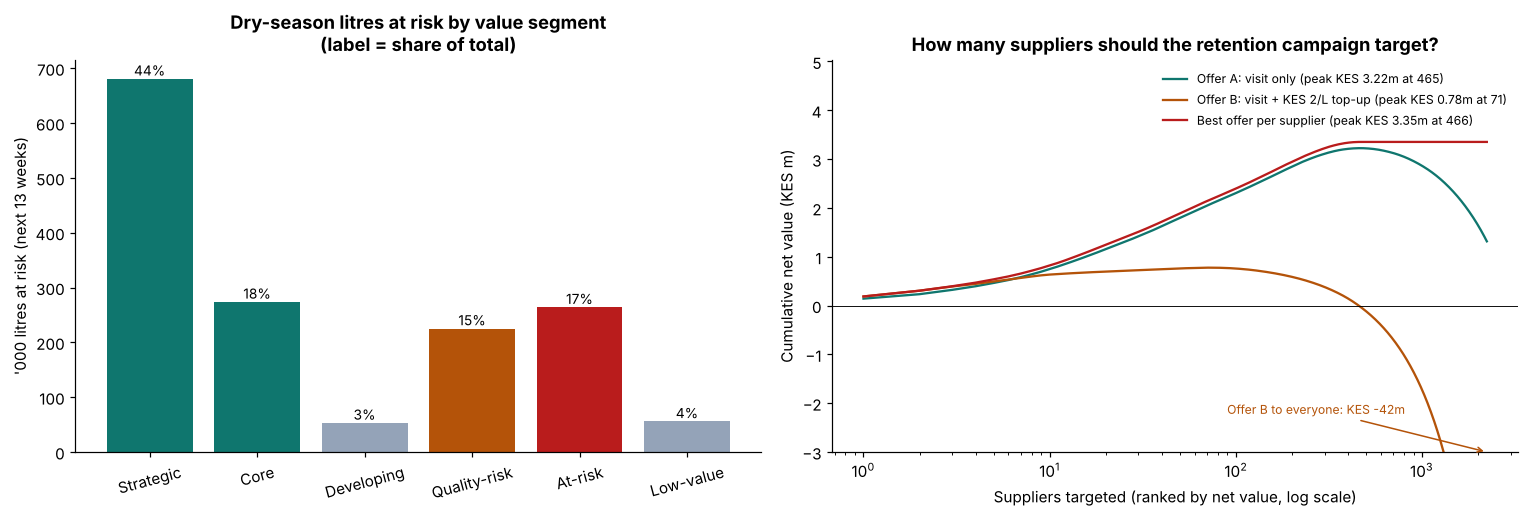

Targeted: 466 of 2,229 suppliers | expected litres retained: 349,190 | net value: KES 3.35m | cost: KES 0.84m


best_action,Field-officer visit,Visit + KES 2/L top-up,All
supplier_type,,,
Commercial farm,198,4,202
Farmer group/cooperative,162,0,162
Smallholder,55,47,102
All,415,51,466


,targeted,litres_retained,net_value_kes
value_segment,,,
Strategic,232.0,167104.0,1657247.0
Core,90.0,43084.0,382003.0
Quality-risk,69.0,47618.0,458571.0
At-risk,43.0,82016.0,811290.0
Low-value,32.0,9369.0,42954.0


In [24]:
MARGIN, VISIT, SAVE_A, TOPUP, SAVE_B = 12, 1_500, .25, 2, .40
p_, L_ = A.churn_prob.values, A.exp_litres_13w.values
A["net_A"] = p_ * SAVE_A * L_ * MARGIN - VISIT
A["net_B"] = p_ * SAVE_B * L_ * MARGIN - VISIT - TOPUP * L_ * (1 - p_ + SAVE_B * p_)
A["best_action"] = np.select([(A.net_B > A.net_A) & (A.net_B > 0), A.net_A > 0], ["Visit + KES 2/L top-up", "Field-officer visit"], "No paid action")
A["best_net"] = A[["net_A", "net_B"]].max(axis=1).clip(lower=0)
A["litres_saved"] = np.select([A.best_action == "Visit + KES 2/L top-up", A.best_action == "Field-officer visit"],
                              [p_ * SAVE_B * L_, p_ * SAVE_A * L_], 0)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
r = risk_table("value_segment", VSEG)
ax[0].bar(r.index, r.litres_at_risk / 1000, color=[TEAL, TEAL, GREY, AMBER, RED, GREY])
for i, (v, s) in enumerate(zip(r.litres_at_risk, r.share_of_litres_at_risk)):
    ax[0].text(i, v / 1000, f"{s:.0%}", ha="center", va="bottom", fontsize=9)
ax[0].set(ylabel="'000 litres at risk (next 13 weeks)", title="Dry-season litres at risk by value segment\n(label = share of total)")
ax[0].tick_params(axis="x", rotation=15)
for col, c, lab in (("net_A", TEAL, "Offer A: visit only"), ("net_B", AMBER, "Offer B: visit + KES 2/L top-up"), ("best_net", RED, "Best offer per supplier")):
    v = np.sort(A[col].values)[::-1]; cum = np.cumsum(v) / 1e6
    ax[1].plot(np.arange(1, len(v) + 1), cum, color=c, label=f"{lab} (peak KES {cum.max():.2f}m at {cum.argmax()+1:,})")
ax[1].axhline(0, color="black", lw=.6); ax[1].set_xscale("log")
ax[1].set_ylim(-3, A.best_net.sum() / 1e6 * 1.5)
ax[1].annotate(f"Offer B to everyone: KES {A.net_B.sum()/1e6:,.0f}m", (len(A), -3), xytext=(-170, 25), textcoords="offset points",
               fontsize=8, color=AMBER, arrowprops=dict(arrowstyle="->", color=AMBER))
ax[1].set(xlabel="Suppliers targeted (ranked by net value, log scale)", ylabel="Cumulative net value (KES m)",
          title="How many suppliers should the retention campaign target?")
ax[1].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "10_litres_at_risk_and_campaign.png", dpi=150); plt.show()

plan = A[A.best_action != "No paid action"]
print(f"Targeted: {len(plan):,} of {len(A):,} suppliers | expected litres retained: {plan.litres_saved.sum():,.0f} "
      f"| net value: KES {plan.best_net.sum()/1e6:,.2f}m | cost: KES {(VISIT*len(plan) + (TOPUP*plan.exp_litres_13w*(1-plan.churn_prob+SAVE_B*plan.churn_prob))[plan.best_action.str.startswith('Visit +')].sum())/1e6:,.2f}m")
display(pd.crosstab(plan.supplier_type, plan.best_action, margins=True))
plan.groupby("value_segment").agg(targeted=("supplier_id", "size"), litres_retained=("litres_saved", "sum"),
                                  net_value_kes=("best_net", "sum")).reindex(VSEG).dropna().round(0)

In [25]:
breakeven_L = VISIT / (MARGIN * SAVE_A)
print(f"Break-even for a visit: p x L >= {breakeven_L:,.0f} litres at risk. A smallholder at the median "
      f"{A.loc[A.supplier_type=='Smallholder','avg_daily_litres_13w'].median():.0f} L/day delivers ~"
      f"{A.loc[A.supplier_type=='Smallholder','exp_litres_13w'].median():,.0f} L in 13 weeks, so a visit only pays if p >= "
      f"{breakeven_L / A.loc[A.supplier_type=='Smallholder','exp_litres_13w'].median():.0%}.")
export_cols = ["supplier_id", "supplier_type", "centre_name", "county", "value_segment", "cluster", "quadrant", "litres_per_day_52w",
               "litres_trend", "rejection_rate", "price_gap_kes", "payment_delay_days", "advisory_visits_180d", "churn_prob",
               "exp_litres_13w", "litres_at_risk", "best_action", "best_net"]
A.sort_values("best_net", ascending=False)[export_cols].round(4).to_csv(OUT / "churn_risk_scores.csv", index=False)
S[["supplier_id", "supplier_type", "centre_name", "abc_class", "reliable", "quality_risk", "fading", "value_segment", "cluster", "quadrant"]] \
    .to_csv(OUT / "supplier_segments.csv", index=False)
A[["supplier_id"] + FEATS + ["litres_per_day_52w", "fat_pct", "snf_pct", "litres_trend", "churned"]].round(8) \
    .to_csv(OUT / "supplier_features.csv", index=False)
print("Saved: churn_risk_scores.csv (ranked action list), supplier_segments.csv, supplier_features.csv (for the R cross-check)")

Break-even for a visit: p x L >= 500 litres at risk. A smallholder at the median 21 L/day delivers ~1,413 L in 13 weeks, so a visit only pays if p >= 35%.
Saved: churn_risk_scores.csv (ranked action list), supplier_segments.csv, supplier_features.csv (for the R cross-check)


**Interpretation:**

* **Under these assumptions the best plan targets 466 of 2,229 suppliers** and is expected to retain about **349,000 litres** through the dry season, for a net value of about **KES 3.35m** on a spend of KES 0.84m.
* **The field-officer visit is the workhorse** (415 suppliers). **The price top-up is worth paying only to 51 suppliers**, mostly high-risk smallholders. A blanket KES 2/L top-up for every active supplier would *lose* about **KES 42m** over the 13 weeks, because most of it goes to suppliers who were going to stay anyway. **Targeted price matching beats across-the-board price rises.**
* **Strategic suppliers dominate the plan** (232 of 466 targeted, KES 1.66m of the net value), even though their churn rate is the lowest. For a 500-litre/day cooperative, even a 5% risk is worth a KES 1,500 visit. This is the case for a **key-account programme for bulk suppliers**.
* **For a typical smallholder a paid visit rarely pays.** At the median 21 L/day, a visit breaks even only if churn probability is ≥ 35%. Smallholders need **cheaper channels**: group meetings, SMS and M-Pesa payment alerts, and extension days at the collection centre. These reach many farmers at a fraction of the cost.
* These numbers are only as good as the assumed save rates and margin. A **randomised pilot** (offer the visit to half of a high-risk list, compare churn) is the next step before scaling.

The exported **`churn_risk_scores.csv`** is the ranked action list. For each supplier it gives the segment, warning signals (trend, rejection rate, price gap, payment delay, visits), churn probability, litres at risk and the recommended action.

## 15. Recommended actions per segment

| Segment / signal | Action | Owner |
|---|---|---|
| **Strategic** (12% of suppliers, 64% of litres) | Key-account management: named officer, payment on or before the due date, quarterly price review against the local competitor price, priority for credit and vet services | Milk procurement manager |
| **Core** | Stabilise and grow: supply agreements for the larger farms, extension packages, cooling support where distance causes sour milk | Area field officers |
| **Developing** | Grow yield per cow: AI, fodder and feed-credit packages, farmer-group membership to cut collection cost | Extension team |
| **Quality-risk** | Quality training *with* a follow-up visit after every rejection (training is protective once rejection is controlled for); antibiotic withdrawal-period education; strip-test kits for bulk suppliers | QA + extension |
| **At-risk** (fading) | Visit within 7 days of the flag; find the cause (price, late payment, rejection, distance); targeted price match only where the expected value supports it | Field officers + procurement |
| **Low-value** | Lowest-cost service: group collection points, M-Pesa payments, SMS updates; no individual field visits | Centre clerks |
| **Price gap > KES 1/L** (any segment) | Monthly competitor price survey by county; *targeted* quality / volume bonuses instead of blanket base-price rises, especially going into the dry season | Procurement + finance |
| **Payment delay** (centres averaging > 7 days) | Fix the payment run: pay on the 10th, move bank-paid farmers to faster rails, publish payment dates in advance | Finance |

## 16. Where supplier segmentation and churn analytics are used

| Sector | Segmentation use | Churn / attrition use |
|---|---|---|
| **Dairy & fresh produce** (milk, tea, coffee, horticulture) | Supplier tiering by volume, quality and reliability; extension targeting | Side-selling early warning; dry-season retention budgets |
| **FMCG manufacturing** | Kraljic / ABC supplier portfolios for raw and packaging materials | Supplier-exit and single-source risk monitoring |
| **Agri-input & out-grower schemes** (sugar, tobacco, barley) | Farmer productivity and repayment segments | Contract default and diversion of the crop to other buyers |
| **Microfinance & SACCOs** | Member value and savings behaviour | Member dormancy and exit |
| **Logistics & transport** | Carrier / transporter scorecards | Losing reliable transporters in peak season |
| **Retail & e-commerce marketplaces** | Seller tiers by GMV and service quality | Seller churn to rival platforms |
| **Healthcare supply chains** | Vendor performance tiers | Vendor failure risk for essential medicines |
| **Gig & field-force platforms** | Rider / agent productivity segments | Agent drop-out prediction |

## 17. Limitations and next steps

* **Synthetic data:** effect sizes are illustrative. On real ERP data, validate on a later snapshot (an **out-of-time** test) as well as a random split. The generator also allows a 29 June 2025 snapshot for this purpose.
* **Small number of events:** about 250 churners in total, and about 60 in the test set, so AUC and odds ratios carry real uncertainty. Weak effects (credit, group membership) may be real but under-powered.
* **Prediction ≠ prevention:** the campaign economics assume save rates. Test the offers with a **randomised control group** (uplift modelling) before scaling, so you measure suppliers *saved*, not just suppliers *predicted*.
* **Partial churn:** many farmers side-sell *part* of their milk for months without leaving. A share-of-production model (litres delivered ÷ estimated herd output) would catch this earlier than full churn.
* **Unobserved drivers:** this data holds no record of farmer satisfaction, competitor visits or household shocks. A short field-officer survey would add strong signals.
* **Survival analysis** (Cox models) would estimate *when* a supplier will leave, not just whether, and use every snapshot instead of one.
* **Monitoring:** rescore monthly, and watch calibration closely at the start of each dry season, when competitor behaviour shifts fastest.